In [2]:
from pathlib import Path

import healpy as hp
import numpy as np
import pandas as pd


# ==================================================
# Settings
# ==================================================

root = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

src = root / "src"


e1_files = [
    src / f"E1_fgres_filter_r{r:03d}.fits"
    for r in range(10)
]


null_map_dir = (
    root
    / "null_mask_fg_iterative_inpainted"
)

null_files = sorted(
    null_map_dir.glob(
        "null_r???.fits"
    )
)

if len(null_files) != 100:
    raise RuntimeError(
        f"Expected 100 null maps, "
        f"found {len(null_files)}."
    )

print(
    "Null maps used:",
    len(null_files),
)


mask_file = (
    src
    / "COM_Mask_CMB-common-Mask-Int_128_R3.00.fits"
)

filter_file = (
    root
    / "SW_Doppler_ISW_filter_lmax300.dat"
)


nside = 128
nphi = 512
m_min = 2

alpha_deg = 30.0

mask_threshold = 0.5
d_min_joint_samples = 34
d_filter_lmax = 300

orientable = True


# ==================================================
# Four known E1 alpha=30 pairs + control
# ==================================================

geometries = [
    {
        "name": "E1 alpha30 pair 1",
        "theta_i": 54.68,
        "phi_i": 225.00,
        "theta_j": 125.32,
        "phi_j": 45.00,
    },
    {
        "name": "E1 alpha30 pair 2",
        "theta_i": 54.68,
        "phi_i": 45.00,
        "theta_j": 125.32,
        "phi_j": 225.00,
    },
    {
        "name": "E1 alpha30 pair 3",
        "theta_i": 54.68,
        "phi_i": 135.00,
        "theta_j": 125.32,
        "phi_j": 315.00,
    },
    {
        "name": "E1 alpha30 pair 4",
        "theta_i": 125.32,
        "phi_i": 135.00,
        "theta_j": 54.68,
        "phi_j": 315.00,
    },
]


# ==================================================
# Convert known E1 centres to NSIDE=128 pixels
# ==================================================

for geometry in geometries:

    if "pixel_i" not in geometry:

        geometry["pixel_i"] = hp.ang2pix(
            nside,
            np.deg2rad(
                geometry["theta_i"]
            ),
            np.deg2rad(
                geometry["phi_i"]
            ),
        )

        geometry["pixel_j"] = hp.ang2pix(
            nside,
            np.deg2rad(
                geometry["theta_j"]
            ),
            np.deg2rad(
                geometry["phi_j"]
            ),
        )

    print(
        geometry["name"],
        "pixel_i =",
        geometry["pixel_i"],
        "pixel_j =",
        geometry["pixel_j"],
    )


# ==================================================
# Read mask
# ==================================================

obs_mask = hp.read_map(
    mask_file,
    field=0,
    dtype=np.float64,
)


# ==================================================
# Read SW filter
# ==================================================

filter_table = np.loadtxt(
    filter_file,
    comments="#",
)

d_filter = np.zeros(
    d_filter_lmax + 1,
    dtype=np.float64,
)

filter_ell = (
    filter_table[:, 0]
    .astype(int)
)

filter_value = (
    filter_table[:, 1]
)

inside = (
    (filter_ell >= 0)
    & (filter_ell <= d_filter_lmax)
)

d_filter[
    filter_ell[inside]
] = filter_value[inside]


# ==================================================
# Apply SW filter to a full map
# ==================================================

def apply_d_filter(
    input_map,
):

    alm = hp.map2alm(
        input_map,
        lmax=d_filter_lmax,
    )

    filtered_alm = hp.almxfl(
        alm,
        d_filter,
    )

    return hp.alm2map(
        filtered_alm,
        nside=nside,
        lmax=d_filter_lmax,
    )


# ==================================================
# Sample one circle
# ==================================================

def sample_circle(
    sky_map,
    pixel,
    alpha_deg,
):

    theta, phi = hp.pix2ang(
        nside,
        pixel,
    )

    alpha = np.deg2rad(
        alpha_deg
    )

    rotation_matrix = np.array(
        [
            [
                np.cos(theta) * np.cos(phi),
                -np.sin(phi),
                np.sin(theta) * np.cos(phi),
            ],
            [
                np.cos(theta) * np.sin(phi),
                np.cos(phi),
                np.sin(theta) * np.sin(phi),
            ],
            [
                -np.sin(theta),
                0.0,
                np.cos(theta),
            ],
        ]
    )

    phi_ring = (
        2.0
        * np.pi
        * np.arange(
            1,
            nphi + 1,
        )
        / nphi
    )

    local_vectors = np.vstack(
        [
            np.sin(alpha)
            * np.cos(phi_ring),

            np.sin(alpha)
            * np.sin(phi_ring),

            np.full(
                nphi,
                np.cos(alpha),
            ),
        ]
    )

    sky_vectors = (
        rotation_matrix
        @ local_vectors
    )

    theta_ring = np.arccos(
        np.clip(
            sky_vectors[2],
            -1.0,
            1.0,
        )
    )

    phi_ring_sky = (
        np.arctan2(
            sky_vectors[1],
            sky_vectors[0],
        )
        + np.pi
    )

    ring_pixels = hp.ang2pix(
        nside,
        theta_ring,
        phi_ring_sky,
    )

    temperature = (
        sky_map[
            ring_pixels
        ]
    )

    valid = (
        obs_mask[
            ring_pixels
        ]
        >= mask_threshold
    )

    modes = np.fft.rfft(
        temperature
    )

    modes[:m_min] = 0.0

    temperature = np.fft.irfft(
        modes,
        n=nphi,
    )

    return (
        temperature,
        valid,
    )


# ==================================================
# FFT calculation of D_diff(beta)
# ==================================================

def get_d_diff_curve_fft(
    sky_map,
    pixel_i,
    pixel_j,
):

    ring_i, valid_i = sample_circle(
        sky_map,
        pixel_i,
        alpha_deg,
    )

    ring_j, valid_j = sample_circle(
        sky_map,
        pixel_j,
        alpha_deg,
    )


    delta_t_i = (
        np.roll(
            ring_i,
            -1,
        )
        - ring_i
    )

    valid_delta_i = (
        valid_i
        & np.roll(
            valid_i,
            -1,
        )
    )


    if orientable:

        delta_t_j = (
            np.roll(
                ring_j,
                1,
            )
            - ring_j
        )

        valid_delta_j = (
            valid_j
            & np.roll(
                valid_j,
                1,
            )
        )

        def all_beta_sum(
            x,
            y,
        ):

            return np.fft.ifft(
                np.fft.fft(x)
                * np.fft.fft(y)
            ).real


    else:

        delta_t_j = (
            np.roll(
                ring_j,
                -1,
            )
            - ring_j
        )

        valid_delta_j = (
            valid_j
            & np.roll(
                valid_j,
                -1,
            )
        )

        def all_beta_sum(
            x,
            y,
        ):

            return np.fft.ifft(
                np.conj(
                    np.fft.fft(x)
                )
                * np.fft.fft(y)
            ).real


    w_i = valid_delta_i.astype(
        np.float64
    )

    w_j = valid_delta_j.astype(
        np.float64
    )


    numerator = (
        2.0
        * all_beta_sum(
            w_i * delta_t_i,
            w_j * delta_t_j,
        )
    )


    denominator = (
        all_beta_sum(
            w_i * delta_t_i**2,
            w_j,
        )
        +
        all_beta_sum(
            w_i,
            w_j * delta_t_j**2,
        )
    )


    n_joint = np.rint(
        all_beta_sum(
            w_i,
            w_j,
        )
    ).astype(int)

    n_joint = np.clip(
        n_joint,
        0,
        nphi,
    )


    d_diff = np.full(
        nphi,
        np.nan,
    )

    usable = (
        (
            n_joint
            >= d_min_joint_samples
        )
        &
        (
            denominator
            > np.finfo(float).tiny
        )
    )

    d_diff[
        usable
    ] = (
        numerator[
            usable
        ]
        /
        denominator[
            usable
        ]
    )

    return (
        d_diff,
        n_joint,
    )


# ==================================================
# E1 curves for all 10 realisations
# ==================================================

e1_curves = {}


for r, e1_file in enumerate(
    e1_files
):

    rr = f"{r:03d}"

    e1_map = hp.read_map(
        e1_file,
        field=0,
        dtype=np.float64,
    )

    e1_curves[rr] = {}


    for geometry in geometries:

        d_diff, n_joint = (
            get_d_diff_curve_fft(
                e1_map,
                geometry["pixel_i"],
                geometry["pixel_j"],
            )
        )

        e1_curves[
            rr
        ][
            geometry["name"]
        ] = {
            "d_diff": d_diff,
            "n_joint": n_joint,
        }


    print(
        f"Finished E1 r{rr}"
    )


# ==================================================
# Null curves at the same five geometries
# ==================================================

null_curves = {}


for geometry in geometries:

    null_curves[
        geometry["name"]
    ] = {

        "d_diff": np.full(
            (
                100,
                nphi,
            ),
            np.nan,
        ),

        "n_joint": np.zeros(
            (
                100,
                nphi,
            ),
            dtype=int,
        ),
    }


for r, null_file in enumerate(
    null_files
):

    null_map = hp.read_map(
        null_file,
        field=0,
        dtype=np.float64,
    )

    filtered_null_map = (
        apply_d_filter(
            null_map
        )
    )


    for geometry in geometries:

        d_diff, n_joint = (
            get_d_diff_curve_fft(
                filtered_null_map,
                geometry["pixel_i"],
                geometry["pixel_j"],
            )
        )

        name = geometry["name"]

        null_curves[
            name
        ][
            "d_diff"
        ][
            r
        ] = d_diff

        null_curves[
            name
        ][
            "n_joint"
        ][
            r
        ] = n_joint


    if (
        (r + 1) % 10 == 0
        or r == 0
    ):

        print(
            f"Finished null map "
            f"{r + 1}/100"
        )
# ==================================================
# Sanity check:
# E1 and all null maps must have identical N_joint(beta)
# at the same geometry
# ==================================================

for geometry in geometries:

    name = geometry["name"]

    reference_n_joint = (
        e1_curves["000"][name]["n_joint"]
    )

    # All E1 realisations
    for r in range(10):

        rr = f"{r:03d}"

        assert np.array_equal(
            e1_curves[rr][name]["n_joint"],
            reference_n_joint,
        )

    # All 100 null realisations
    for r in range(100):

        assert np.array_equal(
            null_curves[name]["n_joint"][r],
            reference_n_joint,
        )

print(
    "PASS: N_joint(beta) is identical "
    "between E1 and nulls at every geometry."
)

# ==================================================
# Compare E1 max D_diff with 95.4% and 99.7%
# null levels at exactly the same geometry
# ==================================================

rows = []


for r in range(10):

    rr = f"{r:03d}"

    for geometry in geometries:

        name = geometry["name"]


        # ==========================================
        # E1: maximise over beta
        # ==========================================

        e1_d_diff = (
            e1_curves[rr][name]["d_diff"]
        )

        beta_e1 = int(
            np.nanargmax(
                e1_d_diff
            )
        )

        beta_e1_deg = (
            360.0
            * beta_e1
            / nphi
        )

        e1_d_max = float(
            e1_d_diff[
                beta_e1
            ]
        )


        # ==========================================
        # 100 null maps:
        # maximise over beta independently
        # ==========================================

        null_d_diff = (
            null_curves[name]["d_diff"]
        )

        null_d_max = np.nanmax(
            null_d_diff,
            axis=1,
        )


        # ==========================================
        # Null critical levels
        # ==========================================

        null_95 = float(
            np.quantile(
                null_d_max,
                0.954,
            )
        )

        null_997 = float(
            np.quantile(
                null_d_max,
                0.997,
            )
        )


        rows.append(
            {
                "Realisation":
                    f"r{rr}",

                "Geometry":
                    name,

                "E1_D_max":
                    e1_d_max,

                "Null_95.4":
                    null_95,

                "Null_99.7":
                    null_997,

                "Above_95.4":
                    e1_d_max > null_95,

                "Above_99.7":
                    e1_d_max > null_997,
                "E1_beta_max_bin":
                    beta_e1,
            }
        )


result_table = pd.DataFrame(
    rows
)


display(
    result_table.round(
        {
            "E1_D_max": 6,
            "Null_95.4": 6,
            "Null_99.7": 6,
        }
    )
)

Null maps used: 100
E1 alpha30 pair 1 pixel_i = 41536 pixel_j = 154944
E1 alpha30 pair 2 pixel_i = 41280 pixel_j = 155200
E1 alpha30 pair 3 pixel_i = 41408 pixel_j = 155328
E1 alpha30 pair 4 pixel_i = 155072 pixel_j = 41664
Finished E1 r000
Finished E1 r001
Finished E1 r002
Finished E1 r003
Finished E1 r004
Finished E1 r005
Finished E1 r006
Finished E1 r007
Finished E1 r008
Finished E1 r009
Finished null map 1/100
Finished null map 10/100
Finished null map 20/100
Finished null map 30/100
Finished null map 40/100
Finished null map 50/100
Finished null map 60/100
Finished null map 70/100
Finished null map 80/100
Finished null map 90/100
Finished null map 100/100
PASS: N_joint(beta) is identical between E1 and nulls at every geometry.


,Realisation,Geometry,E1_D_max,Null_95.4,Null_99.7,Above_95.4,Above_99.7,E1_beta_max_bin
0,r000,E1 alpha30 pair 1,0.232384,0.288195,0.307504,False,False,510
1,r000,E1 alpha30 pair 2,0.431858,0.212580,0.250828,True,True,510
2,r000,E1 alpha30 pair 3,0.266386,0.263198,0.290506,True,False,510
3,r000,E1 alpha30 pair 4,0.251525,0.270646,0.287689,False,False,36
4,r001,E1 alpha30 pair 1,0.300085,0.288195,0.307504,True,False,510
5,r001,E1 alpha30 pair 2,0.275662,0.212580,0.250828,True,True,510
6,r001,E1 alpha30 pair 3,0.381719,0.263198,0.290506,True,True,510
7,r001,E1 alpha30 pair 4,0.338264,0.270646,0.287689,True,True,510
8,r002,E1 alpha30 pair 1,0.331634,0.288195,0.307504,True,True,510
9,r002,E1 alpha30 pair 2,0.346153,0.212580,0.250828,True,True,510


## β-level null standardisation

For a fixed circle geometry $(\alpha,i,j)$, let

$$
D^{\mathrm{diff}}(\beta)
$$

be the statistic evaluated at phase shift $\beta$.

Using the 1500 null simulations, define

$$
\mu_0(\beta)
=
\left\langle
D^{\mathrm{diff}}_{\mathrm{null}}(\beta)
\right\rangle,
$$

and

$$
\sigma_0(\beta)
=
\mathrm{Std}
\left[
D^{\mathrm{diff}}_{\mathrm{null}}(\beta)
\right].
$$

The standardised statistic is

$$
Z(\beta)
=
\frac{
D^{\mathrm{diff}}(\beta)-\mu_0(\beta)
}{
\sigma_0(\beta)
}.
$$

We then compare

$$
D^{\mathrm{diff}}_{\max}
=
\max_{\beta} D^{\mathrm{diff}}(\beta),
$$

with

$$
Z_{\max}
=
\max_{\beta} Z(\beta).
$$

For the null distribution of $Z_{\max}$, each null realisation is
standardised using $\mu_0(\beta)$ and $\sigma_0(\beta)$ calculated from
the other 1499 null maps (leave-one-out), before maximising over $\beta$.

The 95.4% and 99.7% critical levels are obtained from the corresponding
null distributions of $D^{\mathrm{diff}}_{\max}$ and $Z_{\max}$.

In [ ]:
# ==================================================
# 1500-null beta-level standardisation test
#
# Z(beta) =
#     [D_diff(beta) - mean_null(beta)]
#     / std_null(beta)
#
# mean and std are evaluated at the exact same
# (alpha, i, j, beta).
# ==================================================


# ==================================================
# Load the new 1500 null maps
# ==================================================

null_map_dir = (
    root
    / "null_standardisation_1500"
)

null_files = sorted(
    null_map_dir.glob(
        "null_r????.fits"
    )
)

n_null = len(
    null_files
)

if n_null != 1500:
    raise RuntimeError(
        f"Expected 1500 null maps, "
        f"found {n_null}."
    )

print(
    "Null maps used:",
    n_null,
)


# ==================================================
# Calculate D_diff(beta) for all 1500 null maps
# ==================================================

null_curves = {}


for geometry in geometries:

    name = geometry["name"]

    null_curves[name] = {
        "d_diff": np.full(
            (
                n_null,
                nphi,
            ),
            np.nan,
        ),

        "n_joint": np.zeros(
            (
                n_null,
                nphi,
            ),
            dtype=int,
        ),
    }


for r, null_file in enumerate(
    null_files
):

    null_map = hp.read_map(
        null_file,
        field=0,
        dtype=np.float64,
    )

    filtered_null_map = (
        apply_d_filter(
            null_map
        )
    )


    for geometry in geometries:

        name = geometry["name"]

        d_diff, n_joint = (
            get_d_diff_curve_fft(
                filtered_null_map,
                geometry["pixel_i"],
                geometry["pixel_j"],
            )
        )

        null_curves[
            name
        ][
            "d_diff"
        ][r] = d_diff

        null_curves[
            name
        ][
            "n_joint"
        ][r] = n_joint


    if (
        (r + 1) % 100 == 0
        or r == 0
    ):
        print(
            f"Finished null map "
            f"{r + 1}/{n_null}"
        )


# ==================================================
# Check N_joint(beta)
# ==================================================

for geometry in geometries:

    name = geometry["name"]

    reference_n_joint = (
        null_curves[
            name
        ][
            "n_joint"
        ][0]
    )

    assert np.all(
        null_curves[
            name
        ][
            "n_joint"
        ]
        == reference_n_joint
    )

    for r in range(10):

        rr = f"{r:03d}"

        assert np.array_equal(
            e1_curves[
                rr
            ][
                name
            ][
                "n_joint"
            ],
            reference_n_joint,
        )


print(
    "PASS: N_joint(beta) is identical "
    "between E1 and all 1500 nulls."
)


# ==================================================
# Build beta-level null calibration
# ==================================================

beta_calibration = {}


for geometry in geometries:

    name = geometry["name"]

    null_d = (
        null_curves[
            name
        ][
            "d_diff"
        ]
    )


    # ==============================================
    # Proper beta-level mean and std
    # ==============================================

    mean_beta = np.nanmean(
        null_d,
        axis=0,
    )

    std_beta = np.nanstd(
        null_d,
        axis=0,
        ddof=1,
    )


    # ==============================================
    # Raw D_diff max null distribution
    # ==============================================

    null_raw_d_max = np.nanmax(
        null_d,
        axis=1,
    )

    raw_null_95 = float(
        np.nanquantile(
            null_raw_d_max,
            0.954,
        )
    )

    raw_null_997 = float(
        np.nanquantile(
            null_raw_d_max,
            0.997,
        )
    )


    # ==============================================
    # Null Z_max distribution
    #
    # Each null must be standardized using
    # mean/std calculated from the OTHER 1499 nulls.
    # ==============================================

    null_z_max = np.full(
        n_null,
        np.nan,
    )


    for r in range(
        n_null
    ):

        keep = np.ones(
            n_null,
            dtype=bool,
        )

        keep[r] = False


        mean_loo = np.nanmean(
            null_d[keep],
            axis=0,
        )

        std_loo = np.nanstd(
            null_d[keep],
            axis=0,
            ddof=1,
        )


        z_null = np.full(
            nphi,
            np.nan,
        )


        usable = (
            np.isfinite(
                null_d[r]
            )
            &
            np.isfinite(
                mean_loo
            )
            &
            np.isfinite(
                std_loo
            )
            &
            (
                std_loo
                > 1.0e-12
            )
        )


        z_null[
            usable
        ] = (
            (
                null_d[
                    r,
                    usable
                ]
                -
                mean_loo[
                    usable
                ]
            )
            /
            std_loo[
                usable
            ]
        )


        if np.any(
            np.isfinite(
                z_null
            )
        ):

            null_z_max[r] = (
                np.nanmax(
                    z_null
                )
            )


    beta_calibration[
        name
    ] = {
        "mean_beta":
            mean_beta,

        "std_beta":
            std_beta,

        "raw_null_95":
            raw_null_95,

        "raw_null_997":
            raw_null_997,

        "null_zmax_95":
            float(
                np.nanquantile(
                    null_z_max,
                    0.954,
                )
            ),

        "null_zmax_997":
            float(
                np.nanquantile(
                    null_z_max,
                    0.997,
                )
            ),
    }


# ==================================================
# Apply raw D_diff and standardized Z to E1
# ==================================================

rows = []


for r in range(10):

    rr = f"{r:03d}"


    for geometry in geometries:

        name = geometry["name"]


        e1_d = (
            e1_curves[
                rr
            ][
                name
            ][
                "d_diff"
            ]
        )

        e1_n_joint = (
            e1_curves[
                rr
            ][
                name
            ][
                "n_joint"
            ]
        )


        # ==========================================
        # Raw D_diff
        # ==========================================

        raw_beta = int(
            np.nanargmax(
                e1_d
            )
        )

        raw_d_max = float(
            e1_d[
                raw_beta
            ]
        )


        raw_null_95 = (
            beta_calibration[
                name
            ][
                "raw_null_95"
            ]
        )

        raw_null_997 = (
            beta_calibration[
                name
            ][
                "raw_null_997"
            ]
        )


        # ==========================================
        # Proper standardized statistic
        #
        # Z(beta) =
        # [D_diff(beta) - mean(beta)]
        # / std(beta)
        # ==========================================

        mean_beta = (
            beta_calibration[
                name
            ][
                "mean_beta"
            ]
        )

        std_beta = (
            beta_calibration[
                name
            ][
                "std_beta"
            ]
        )


        z_beta = np.full(
            nphi,
            np.nan,
        )


        usable = (
            np.isfinite(
                e1_d
            )
            &
            np.isfinite(
                mean_beta
            )
            &
            np.isfinite(
                std_beta
            )
            &
            (
                std_beta
                > 1.0e-12
            )
        )


        z_beta[
            usable
        ] = (
            (
                e1_d[
                    usable
                ]
                -
                mean_beta[
                    usable
                ]
            )
            /
            std_beta[
                usable
            ]
        )


        standardized_beta = int(
            np.nanargmax(
                z_beta
            )
        )

        standardized_z_max = float(
            z_beta[
                standardized_beta
            ]
        )


        null_zmax_95 = (
            beta_calibration[
                name
            ][
                "null_zmax_95"
            ]
        )

        null_zmax_997 = (
            beta_calibration[
                name
            ][
                "null_zmax_997"
            ]
        )


        # ==========================================
        # Save
        # ==========================================

        rows.append(
            {
                "Realisation":
                    f"r{rr}",

                "Geometry":
                    name,

                "Raw_beta_bin":
                    raw_beta,

                "Raw_beta_deg":
                    (
                        360.0
                        * raw_beta
                        / nphi
                    ),

                "Raw_D_max":
                    raw_d_max,

                "Raw_Above_95.4":
                    (
                        raw_d_max
                        > raw_null_95
                    ),

                "Raw_Above_99.7":
                    (
                        raw_d_max
                        > raw_null_997
                    ),

                "Raw_N_joint":
                    int(
                        e1_n_joint[
                            raw_beta
                        ]
                    ),

                "Standardized_beta_bin":
                    standardized_beta,

                "Standardized_beta_deg":
                    (
                        360.0
                        * standardized_beta
                        / nphi
                    ),

                "Standardized_Z_max":
                    standardized_z_max,

                "Standardized_D":
                    float(
                        e1_d[
                            standardized_beta
                        ]
                    ),

                "Mean_null":
                    float(
                        mean_beta[
                            standardized_beta
                        ]
                    ),

                "Std_null":
                    float(
                        std_beta[
                            standardized_beta
                        ]
                    ),

                "Standardized_N_joint":
                    int(
                        e1_n_joint[
                            standardized_beta
                        ]
                    ),

                "Above_Zmax_95.4":
                    (
                        standardized_z_max
                        > null_zmax_95
                    ),

                "Above_Zmax_99.7":
                    (
                        standardized_z_max
                        > null_zmax_997
                    ),
            }
        )


result_table = pd.DataFrame(
    rows
)


# ==================================================
# Full result table
# ==================================================

display(
    result_table.round(
        {
            "Raw_beta_deg": 3,
            "Raw_D_max": 6,

            "Standardized_beta_deg": 3,
            "Standardized_Z_max": 6,
            "Standardized_D": 6,

            "Mean_null": 6,
            "Std_null": 6,
        }
    )
)


# ==================================================
# Clean summary
# ==================================================

raw_correct = (
    result_table[
        "Raw_beta_bin"
    ]
    == 510
)

standardized_correct = (
    result_table[
        "Standardized_beta_bin"
    ]
    == 510
)


summary = pd.DataFrame(
    {
        "Statistic": [
            "Raw D_diff",
            "Raw D_diff",
            "Standardized Z",
            "Standardized Z",
        ],

        "CL": [
            "95.4%",
            "99.7%",
            "95.4%",
            "99.7%",
        ],

        "beta=510 / 40": [
            np.count_nonzero(
                raw_correct
            ),

            np.count_nonzero(
                raw_correct
            ),

            np.count_nonzero(
                standardized_correct
            ),

            np.count_nonzero(
                standardized_correct
            ),
        ],

        "Above CL / 40": [
            np.count_nonzero(
                result_table[
                    "Raw_Above_95.4"
                ]
            ),

            np.count_nonzero(
                result_table[
                    "Raw_Above_99.7"
                ]
            ),

            np.count_nonzero(
                result_table[
                    "Above_Zmax_95.4"
                ]
            ),

            np.count_nonzero(
                result_table[
                    "Above_Zmax_99.7"
                ]
            ),
        ],

        "Above CL + beta=510": [
            np.count_nonzero(
                result_table[
                    "Raw_Above_95.4"
                ]
                & raw_correct
            ),

            np.count_nonzero(
                result_table[
                    "Raw_Above_99.7"
                ]
                & raw_correct
            ),

            np.count_nonzero(
                result_table[
                    "Above_Zmax_95.4"
                ]
                & standardized_correct
            ),

            np.count_nonzero(
                result_table[
                    "Above_Zmax_99.7"
                ]
                & standardized_correct
            ),
        ],

        "Above CL + wrong beta": [
            np.count_nonzero(
                result_table[
                    "Raw_Above_95.4"
                ]
                & ~raw_correct
            ),

            np.count_nonzero(
                result_table[
                    "Raw_Above_99.7"
                ]
                & ~raw_correct
            ),

            np.count_nonzero(
                result_table[
                    "Above_Zmax_95.4"
                ]
                & ~standardized_correct
            ),

            np.count_nonzero(
                result_table[
                    "Above_Zmax_99.7"
                ]
                & ~standardized_correct
            ),
        ],
    }
)


print()
print(
    "===== 1500-NULL STANDARDISATION ====="
)
print()

display(
    summary
)

In [17]:
# ==================================================
# Clean raw-vs-standardized summary
# ==================================================

raw_correct = (
    result_table["Raw_beta_bin"]
    == 510
)

std_correct = (
    result_table["Standardized_beta_bin"]
    == 510
)


summary = pd.DataFrame(
    [
        {
            "Statistic": "Raw D_diff",
            "CL": "95.4%",
            "beta=510": np.count_nonzero(
                raw_correct
            ),
            "wrong beta": np.count_nonzero(
                ~raw_correct
            ),
            "above CL": np.count_nonzero(
                result_table["Raw_Above_95.4"]
            ),
            "above CL, beta=510": np.count_nonzero(
                result_table["Raw_Above_95.4"]
                & raw_correct
            ),
            "above CL, wrong beta": np.count_nonzero(
                result_table["Raw_Above_95.4"]
                & ~raw_correct
            ),
        },

        {
            "Statistic": "Raw D_diff",
            "CL": "99.7%",
            "beta=510": np.count_nonzero(
                raw_correct
            ),
            "wrong beta": np.count_nonzero(
                ~raw_correct
            ),
            "above CL": np.count_nonzero(
                result_table["Raw_Above_99.7"]
            ),
            "above CL, beta=510": np.count_nonzero(
                result_table["Raw_Above_99.7"]
                & raw_correct
            ),
            "above CL, wrong beta": np.count_nonzero(
                result_table["Raw_Above_99.7"]
                & ~raw_correct
            ),
        },

        {
            "Statistic": "Standardized Z",
            "CL": "95.4%",
            "beta=510": np.count_nonzero(
                std_correct
            ),
            "wrong beta": np.count_nonzero(
                ~std_correct
            ),
            "above CL": np.count_nonzero(
                result_table["Above_Zmax_95.4"]
            ),
            "above CL, beta=510": np.count_nonzero(
                result_table["Above_Zmax_95.4"]
                & std_correct
            ),
            "above CL, wrong beta": np.count_nonzero(
                result_table["Above_Zmax_95.4"]
                & ~std_correct
            ),
        },

        {
            "Statistic": "Standardized Z",
            "CL": "99.7%",
            "beta=510": np.count_nonzero(
                std_correct
            ),
            "wrong beta": np.count_nonzero(
                ~std_correct
            ),
            "above CL": np.count_nonzero(
                result_table["Above_Zmax_99.7"]
            ),
            "above CL, beta=510": np.count_nonzero(
                result_table["Above_Zmax_99.7"]
                & std_correct
            ),
            "above CL, wrong beta": np.count_nonzero(
                result_table["Above_Zmax_99.7"]
                & ~std_correct
            ),
        },
    ]
)


display(
    summary
)


print()

print(
    f"Raw beta recovery:          "
    f"{np.count_nonzero(raw_correct)}/40"
)

print(
    f"Standardized beta recovery: "
    f"{np.count_nonzero(std_correct)}/40"
)

,Statistic,CL,beta=510,wrong beta,above CL,"above CL, beta=510","above CL, wrong beta"
0,Raw D_diff,95.4%,37,3,29,29,0
1,Raw D_diff,99.7%,37,3,19,19,0
2,Standardized Z,95.4%,32,8,25,24,1
3,Standardized Z,99.7%,32,8,14,14,0



Raw beta recovery:          37/40
Standardized beta recovery: 32/40


,Geometry,beta_bin,beta_deg,N_joint,sigma_null,is_beta_510
0,E1 alpha30 pair 1,0,0.000000,196,0.085108,False
1,E1 alpha30 pair 1,1,0.703125,196,0.086494,False
2,E1 alpha30 pair 1,2,1.406250,196,0.080333,False
3,E1 alpha30 pair 1,3,2.109375,196,0.087671,False
4,E1 alpha30 pair 1,4,2.812500,196,0.092451,False
5,E1 alpha30 pair 1,5,3.515625,196,0.087936,False
6,E1 alpha30 pair 1,6,4.218750,196,0.093336,False
7,E1 alpha30 pair 1,7,4.921875,196,0.087275,False
8,E1 alpha30 pair 1,8,5.625000,196,0.084022,False
9,E1 alpha30 pair 1,9,6.328125,196,0.085709,False


Correlation between N_joint and sigma_null

E1 alpha30 pair 1: corr(N_joint, sigma_null) = -0.7793
E1 alpha30 pair 2: corr(N_joint, sigma_null) = -0.1796
E1 alpha30 pair 3: corr(N_joint, sigma_null) = -0.5108
E1 alpha30 pair 4: corr(N_joint, sigma_null) = -0.6131


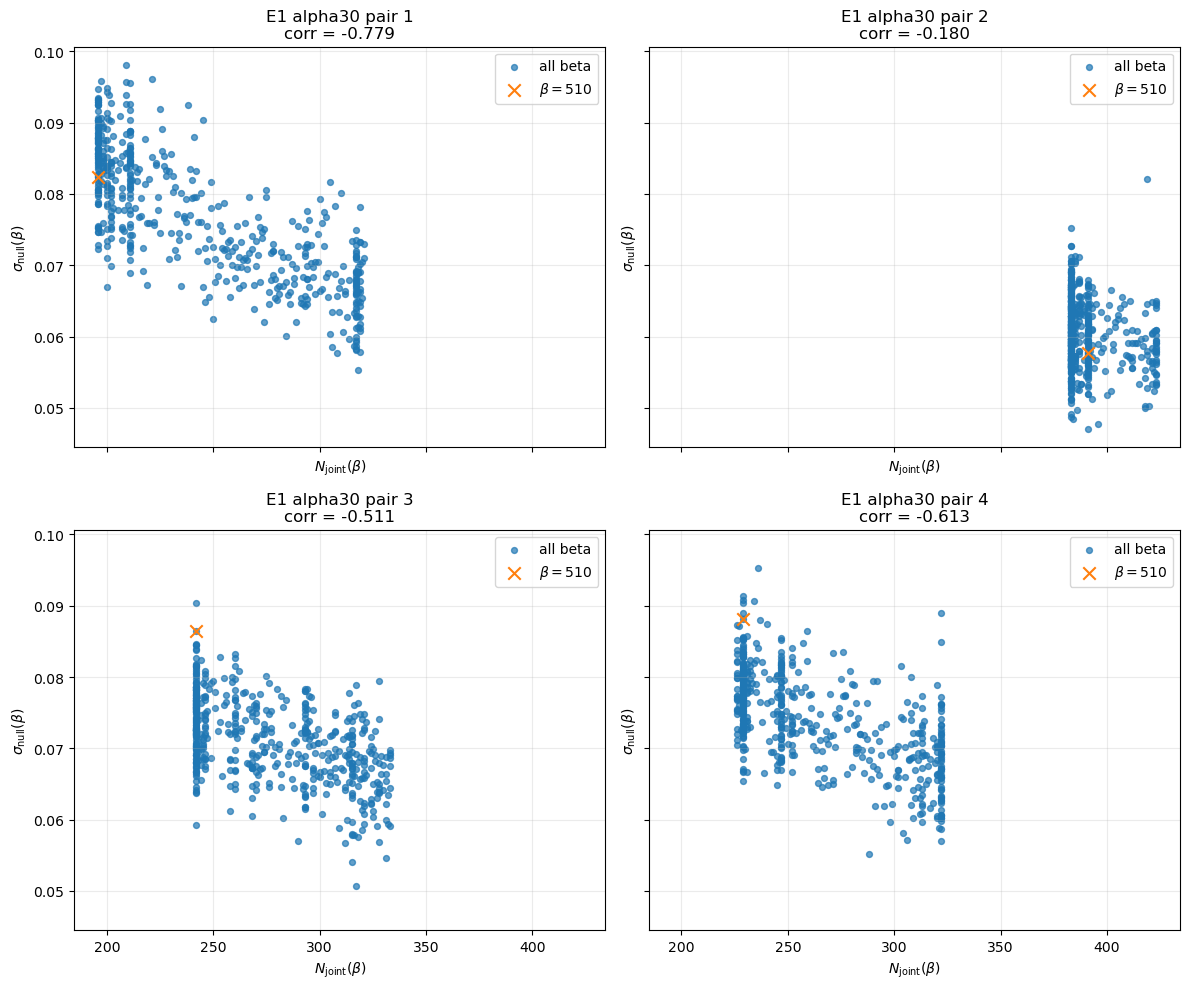

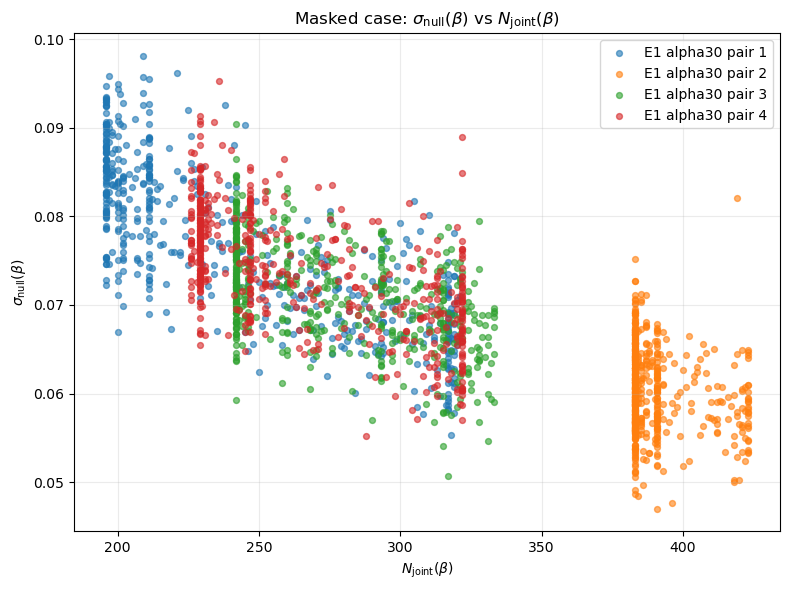

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==================================================
# Build table of N_joint(beta) and sigma_null(beta)
# for each geometry
# ==================================================

rows = []

for geometry in geometries:

    name = geometry["name"]

    # ----------------------------------------------
    # Use one E1 realisation only to read N_joint(beta),
    # because you already checked it is identical across
    # all E1 and null maps at fixed geometry.
    # ----------------------------------------------
    n_joint_beta = e1_curves["000"][name]["n_joint"]

    # ----------------------------------------------
    # Null sigma(beta) from the current calibration
    # ----------------------------------------------
    if "null_std_beta" in beta_calibration[name]:
        sigma_beta = beta_calibration[name]["null_std_beta"]
    else:
        sigma_beta = beta_calibration[name]["scale_beta"]

    for beta_bin in range(len(n_joint_beta)):

        n_joint = n_joint_beta[beta_bin]
        sigma = sigma_beta[beta_bin]

        if np.isfinite(n_joint) and np.isfinite(sigma):

            rows.append(
                {
                    "Geometry": name,
                    "beta_bin": beta_bin,
                    "beta_deg": 360.0 * beta_bin / len(n_joint_beta),
                    "N_joint": int(n_joint),
                    "sigma_null": float(sigma),
                    "is_beta_510": (beta_bin == 510),
                }
            )

sigma_table = pd.DataFrame(rows)

display(
    sigma_table.head(20)
)


# ==================================================
# Very direct summary numbers
# ==================================================

print("Correlation between N_joint and sigma_null")
print()

for geometry in geometries:

    name = geometry["name"]

    sub = sigma_table[
        sigma_table["Geometry"] == name
    ]

    corr = np.corrcoef(
        sub["N_joint"],
        sub["sigma_null"],
    )[0, 1]

    print(
        f"{name}: corr(N_joint, sigma_null) = {corr:.4f}"
    )


# ==================================================
# Plot 1:
# one panel per geometry
# ==================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()

for ax, geometry in zip(axes, geometries):

    name = geometry["name"]

    sub = sigma_table[
        sigma_table["Geometry"] == name
    ]

    beta510 = sub[
        sub["is_beta_510"]
    ]

    ax.scatter(
        sub["N_joint"],
        sub["sigma_null"],
        s=18,
        alpha=0.7,
        label="all beta",
    )

    ax.scatter(
        beta510["N_joint"],
        beta510["sigma_null"],
        s=80,
        marker="x",
        label=r"$\beta=510$",
    )

    corr = np.corrcoef(
        sub["N_joint"],
        sub["sigma_null"],
    )[0, 1]

    ax.set_title(
        f"{name}\n"
        f"corr = {corr:.3f}"
    )

    ax.set_xlabel(
        r"$N_{\rm joint}(\beta)$"
    )

    ax.set_ylabel(
        r"$\sigma_{\rm null}(\beta)$"
    )

    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()


# ==================================================
# Plot 2:
# all geometries together
# ==================================================

plt.figure(figsize=(8, 6))

for geometry in geometries:

    name = geometry["name"]

    sub = sigma_table[
        sigma_table["Geometry"] == name
    ]

    plt.scatter(
        sub["N_joint"],
        sub["sigma_null"],
        s=18,
        alpha=0.6,
        label=name,
    )

plt.xlabel(
    r"$N_{\rm joint}(\beta)$"
)
plt.ylabel(
    r"$\sigma_{\rm null}(\beta)$"
)
plt.title(
    r"Masked case: $\sigma_{\rm null}(\beta)$ vs $N_{\rm joint}(\beta)$"
)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Combined $D^{\mathrm{diff}}$ and null-tail statistic

For each separation $s=1,\ldots,8$, define the temperature difference

$$
\Delta T_i^{(s)}(\phi)
=
T_i(\phi+s)-T_i(\phi),
$$

with the corresponding matched difference on circle $j$.

The combined statistic is formed by summing the raw numerator and denominator over all separations,

$$
D^{\mathrm{diff}}(\beta)
=
\frac{
2\displaystyle\sum_{s=1}^{8}\sum_{\phi}
\Delta T_i^{(s)}(\phi)
\Delta T_j^{(s)}(\phi,\beta)
}{
\displaystyle\sum_{s=1}^{8}\sum_{\phi}
\left[
\left(\Delta T_i^{(s)}(\phi)\right)^2
+
\left(\Delta T_j^{(s)}(\phi,\beta)\right)^2
\right]
}.
$$

The separations are therefore combined before normalisation.

For each $\beta$, define the null exceedance count

$$
R_{\mathrm{null}}(\beta)
=
\#\left\{
D_{\mathrm{null}}^{\mathrm{diff}}(\beta)
\ge
D_{\mathrm{E1}}^{\mathrm{diff}}(\beta)
\right\}.
$$

If $M_{\mathrm{null}}(\beta)$ null realisations are available, the empirical upper-tail survival fraction is

$$
\hat{S}_{\mathrm{null}}(\beta)
=
\frac{
R_{\mathrm{null}}(\beta)
}{
M_{\mathrm{null}}(\beta)
}.
$$

For the discrete Monte Carlo test, we use the usual finite-sample correction

$$
p_{\mathrm{null}}(\beta)
=
\frac{
1+R_{\mathrm{null}}(\beta)
}{
1+M_{\mathrm{null}}(\beta)
},
$$

and define

$$
Q^{\mathrm{diff}}(\beta)
=
-\log_{10}
p_{\mathrm{null}}(\beta).
$$

This discrete quantity has a finite-null floor: when
$R_{\mathrm{null}}=0$, the smallest possible value is

$$
p_{\mathrm{null}}
=
\frac{1}{1+M_{\mathrm{null}}}.
$$

To estimate the upper tail beyond this discrete resolution, we construct a continuous estimate of the null exceedance count.

Below the upper-tail threshold, $R_{\mathrm{null}}(D)$ is interpolated between the empirical null values. In the upper tail, we fit

$$
R_{\mathrm{null}}^{\mathrm{cont}}(D)
=
k\exp\left[b(D-u)\right],
$$

where $u$ is the start of the fitted tail and $k$ is the number of null points included in the tail fit.

Evaluating the continuous tail estimate at the E1 value gives the
continuous estimate of the null survival probability,

$$
\widehat{S}^{\mathrm{cont}}
\left(
D_{\mathrm{E1}}^{\mathrm{diff}}(\beta)
\right)
=
P\!\left(
D_{\mathrm{null}}^{\mathrm{diff}}(\beta)
\ge
D_{\mathrm{E1}}^{\mathrm{diff}}(\beta)
\right)
\approx
\frac{
R_{\mathrm{null}}^{\mathrm{cont}}
\left(
D_{\mathrm{E1}}^{\mathrm{diff}}(\beta)
\right)
}{
M_{\mathrm{null}}(\beta)
}.
$$

We then define

$$
Q_{\mathrm{cont}}^{\mathrm{diff}}(\beta)
=
-\log_{10}
\hat{S}_{\mathrm{null}}^{\mathrm{cont}}(\beta).
$$

We compare the phase shifts selected by maximising
$D^{\mathrm{diff}}$, $Q^{\mathrm{diff}}$, and
$Q_{\mathrm{cont}}^{\mathrm{diff}}$.

**Note:** We later found that using only separations $s=1,2$ gives essentially the same detection performance as using $s=1,\ldots,8$. We therefore use $s=1,2$ to reduce the computational cost.

In [2]:
# D_diff combines s = 1,...,8 by summing raw numerators and denominators,
# then dividing once, as in the blind-search normalisation.
# Unlike the attached Fortran file, even separations are included here.
# N_joint_diff is the MINIMUM count across s, not a sum or average.
# The original continuous_r_null method and its top-20 tail fit are retained.
# Its p-values are fitted estimates, not validated global detection p-values.

from pathlib import Path

import healpy as hp
import numpy as np
import pandas as pd
from IPython.display import display


# ==================================================
# Settings
# ==================================================

root = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

src = root / "src"


e1_files = [
    src / f"E1_fgres_filter_r{r:03d}.fits"
    for r in range(10)
]


null_map_dir = (
    root
    / "null_standardisation_1500"
)

null_files = sorted(
    null_map_dir.glob(
        "null_r????.fits"
    )
)

if len(null_files) != 1500:
    raise RuntimeError(
        f"Expected 1500 null maps, "
        f"found {len(null_files)}."
    )

print(
    "Null maps used:",
    len(null_files),
)


mask_file = (
    src
    / "COM_Mask_CMB-common-Mask-Int_128_R3.00.fits"
)

filter_file = (
    root
    / "SW_Doppler_ISW_filter_lmax300.dat"
)


nside = 128
nphi = 512
m_min = 2

alpha_deg = 30.0

mask_threshold = 0.5
d_min_joint_samples = 34
d_filter_lmax = 300

# All separations 1,...,8; ratio of summed numerators and denominators.
d_diff_max_separation = 8

orientable = True


# Number of largest null D_diff values used
# to fit the continuous upper tail
n_tail_fit = 20


# ==================================================
# Four known E1 alpha=30 pairs + control
# ==================================================

geometries = [
    {
        "name": "E1 alpha30 pair 1",
        "theta_i": 54.68,
        "phi_i": 225.00,
        "theta_j": 125.32,
        "phi_j": 45.00,
    },
    {
        "name": "E1 alpha30 pair 2",
        "theta_i": 54.68,
        "phi_i": 45.00,
        "theta_j": 125.32,
        "phi_j": 225.00,
    },
    {
        "name": "E1 alpha30 pair 3",
        "theta_i": 54.68,
        "phi_i": 135.00,
        "theta_j": 125.32,
        "phi_j": 315.00,
    },
    {
        "name": "E1 alpha30 pair 4",
        "theta_i": 125.32,
        "phi_i": 135.00,
        "theta_j": 54.68,
        "phi_j": 315.00,
    },
    {
        "name": "Control",
        "pixel_i": 98090,
        "pixel_j": 98346,
    },
]


# ==================================================
# Convert known E1 centres to NSIDE=128 pixels
# ==================================================

for geometry in geometries:

    if "pixel_i" not in geometry:

        geometry["pixel_i"] = hp.ang2pix(
            nside,
            np.deg2rad(
                geometry["theta_i"]
            ),
            np.deg2rad(
                geometry["phi_i"]
            ),
        )

        geometry["pixel_j"] = hp.ang2pix(
            nside,
            np.deg2rad(
                geometry["theta_j"]
            ),
            np.deg2rad(
                geometry["phi_j"]
            ),
        )

    print(
        geometry["name"],
        "pixel_i =",
        geometry["pixel_i"],
        "pixel_j =",
        geometry["pixel_j"],
    )


# ==================================================
# Read mask
# ==================================================

obs_mask = hp.read_map(
    mask_file,
    field=0,
    dtype=np.float64,
)


# ==================================================
# Read SW filter
# ==================================================

filter_table = np.loadtxt(
    filter_file,
    comments="#",
)

d_filter = np.zeros(
    d_filter_lmax + 1,
    dtype=np.float64,
)

filter_ell = (
    filter_table[:, 0]
    .astype(int)
)

filter_value = (
    filter_table[:, 1]
)

inside = (
    (filter_ell >= 0)
    & (filter_ell <= d_filter_lmax)
)

d_filter[
    filter_ell[inside]
] = filter_value[inside]


# ==================================================
# Apply SW filter to a full map
# ==================================================

def apply_d_filter(
    input_map,
):

    alm = hp.map2alm(
        input_map,
        lmax=d_filter_lmax,
    )

    filtered_alm = hp.almxfl(
        alm,
        d_filter,
    )

    return hp.alm2map(
        filtered_alm,
        nside=nside,
        lmax=d_filter_lmax,
    )


# ==================================================
# Sample one circle
# ==================================================

def sample_circle(
    sky_map,
    pixel,
    alpha_deg,
):

    theta, phi = hp.pix2ang(
        nside,
        pixel,
    )

    alpha = np.deg2rad(
        alpha_deg
    )

    rotation_matrix = np.array(
        [
            [
                np.cos(theta) * np.cos(phi),
                -np.sin(phi),
                np.sin(theta) * np.cos(phi),
            ],
            [
                np.cos(theta) * np.sin(phi),
                np.cos(phi),
                np.sin(theta) * np.sin(phi),
            ],
            [
                -np.sin(theta),
                0.0,
                np.cos(theta),
            ],
        ]
    )

    phi_ring = (
        2.0
        * np.pi
        * np.arange(
            1,
            nphi + 1,
        )
        / nphi
    )

    local_vectors = np.vstack(
        [
            np.sin(alpha)
            * np.cos(phi_ring),

            np.sin(alpha)
            * np.sin(phi_ring),

            np.full(
                nphi,
                np.cos(alpha),
            ),
        ]
    )

    sky_vectors = (
        rotation_matrix
        @ local_vectors
    )

    theta_ring = np.arccos(
        np.clip(
            sky_vectors[2],
            -1.0,
            1.0,
        )
    )

    phi_ring_sky = (
        np.arctan2(
            sky_vectors[1],
            sky_vectors[0],
        )
        + np.pi
    )

    ring_pixels = hp.ang2pix(
        nside,
        theta_ring,
        phi_ring_sky,
    )

    temperature = (
        sky_map[
            ring_pixels
        ]
    )

    valid = (
        obs_mask[
            ring_pixels
        ]
        >= mask_threshold
    )

    modes = np.fft.rfft(
        temperature
    )

    modes[:m_min] = 0.0

    temperature = np.fft.irfft(
        modes,
        n=nphi,
    )

    return (
        temperature,
        valid,
    )


# ==================================================
# FFT calculation of combined D_diff(beta), s = 1,...,8
# ==================================================

def get_d_diff_curve_fft(
    sky_map,
    pixel_i,
    pixel_j,
):

    # Sample and remove low modes once per ring, not once per separation.
    ring_i, valid_i = sample_circle(sky_map, pixel_i, alpha_deg)
    ring_j, valid_j = sample_circle(sky_map, pixel_j, alpha_deg)

    numerator_total = np.zeros(nphi, dtype=np.float64)
    denominator_total = np.zeros(nphi, dtype=np.float64)

    # Match the blind-search output: minimum count over all included s.
    n_joint = np.full(nphi, nphi, dtype=int)

    # Include EVERY separation: 1, 2, 3, 4, 5, 6, 7, 8.
    for separation_bin in range(1, d_diff_max_separation + 1):

        delta_t_i = np.roll(ring_i, -separation_bin) - ring_i
        valid_delta_i = valid_i & np.roll(valid_i, -separation_bin)

        if orientable:
            # Backward difference on ring j for the orientable convolution.
            delta_t_j = np.roll(ring_j, separation_bin) - ring_j
            valid_delta_j = valid_j & np.roll(valid_j, separation_bin)
        else:
            delta_t_j = np.roll(ring_j, -separation_bin) - ring_j
            valid_delta_j = valid_j & np.roll(valid_j, -separation_bin)

        w_i = valid_delta_i.astype(np.float64)
        w_j = valid_delta_j.astype(np.float64)

        # Reuse the six forward FFTs for the three required inverse FFTs.
        fw_i = np.fft.fft(w_i)
        fw_j = np.fft.fft(w_j)
        fx_i = np.fft.fft(w_i * delta_t_i)
        fx_j = np.fft.fft(w_j * delta_t_j)
        fe_i = np.fft.fft(w_i * delta_t_i**2)
        fe_j = np.fft.fft(w_j * delta_t_j**2)

        if not orientable:
            fw_i = np.conj(fw_i)
            fx_i = np.conj(fx_i)
            fe_i = np.conj(fe_i)

        numerator_total += 2.0 * np.fft.ifft(fx_i * fx_j).real

        denominator_total += np.fft.ifft(
            fe_i * fw_j + fw_i * fe_j
        ).real

        n_joint_s = np.rint(
            np.fft.ifft(fw_i * fw_j).real
        ).astype(int)
        n_joint_s = np.clip(n_joint_s, 0, nphi)
        n_joint = np.minimum(n_joint, n_joint_s)

    # Divide ONCE, after accumulating all eight separations.
    # No 1/8 factor and no average of individually normalised D_s values.
    d_diff = np.full(nphi, np.nan)
    usable = (
        (n_joint >= d_min_joint_samples)
        & (denominator_total > np.finfo(float).tiny)
    )

    d_diff[usable] = np.clip(
        numerator_total[usable] / denominator_total[usable],
        -1.0,
        1.0,
    )

    return d_diff, n_joint


# ==================================================
# Continuous R_null(D)
# ==================================================

def continuous_r_null(
    null_reference,
    d_value,
):

    null_reference = np.asarray(
        null_reference,
        dtype=np.float64,
    )

    null_reference = null_reference[
        np.isfinite(
            null_reference
        )
    ]

    n = len(
        null_reference
    )

    if (
        n < 3
        or not np.isfinite(
            d_value
        )
    ):
        return np.nan


    # Sort from smallest D to largest D
    d_sorted = np.sort(
        null_reference
    )


    # Empirical exceedance count associated
    # with each ordered null value:
    #
    # smallest D -> R = n
    # largest D  -> R = 1
    r_sorted = (
        n
        - np.arange(
            n,
            dtype=np.float64,
        )
    )


    # Number of points used for
    # the upper-tail fit
    k = min(
        n_tail_fit,
        n - 1,
    )


    # First point of the upper tail
    tail_start = (
        n - k
    )

    u = d_sorted[
        tail_start
    ]


    # --------------------------------------------------
    # Below the tail threshold:
    # interpolate R_null(D) continuously
    # between the actual empirical null points
    # --------------------------------------------------

    if d_value < u:

        r_cont = np.interp(
            d_value,
            d_sorted,
            r_sorted,
        )

        return float(
            r_cont
        )


    # --------------------------------------------------
    # Upper tail:
    #
    # R(D) = k exp[b (D - u)]
    #
    # with R(u) = k
    # --------------------------------------------------

    d_tail = d_sorted[
        tail_start:
    ]

    r_tail = r_sorted[
        tail_start:
    ]


    x = (
        d_tail - u
    )

    y = np.log(
        r_tail / k
    )


    # Fit through the fixed point
    #
    # x = 0
    # y = 0
    #
    # so that R(u) = k exactly
    denominator = np.sum(
        x**2
    )

    if denominator <= 0.0:
        return np.nan


    b = (
        np.sum(
            x * y
        )
        / denominator
    )


    # Tail must decrease with increasing D
    if (
        not np.isfinite(
            b
        )
        or b >= 0.0
    ):
        return np.nan


    r_cont = (
        k
        * np.exp(
            b
            * (
                d_value - u
            )
        )
    )


    return max(
        float(
            r_cont
        ),
        np.finfo(float).tiny,
    )


# ==================================================
# E1 curves for all 10 realisations
# ==================================================

e1_curves = {}


for r, e1_file in enumerate(
    e1_files
):

    rr = f"{r:03d}"

    e1_map = hp.read_map(
        e1_file,
        field=0,
        dtype=np.float64,
    )

    e1_curves[rr] = {}


    for geometry in geometries:

        d_diff, n_joint = (
            get_d_diff_curve_fft(
                e1_map,
                geometry["pixel_i"],
                geometry["pixel_j"],
            )
        )

        e1_curves[
            rr
        ][
            geometry["name"]
        ] = {
            "d_diff": d_diff,
            "n_joint": n_joint,
        }


    print(
        f"Finished E1 r{rr}"
    )


# ==================================================
# Null curves at the same five geometries
# ==================================================

null_curves = {}


for geometry in geometries:

    null_curves[
        geometry["name"]
    ] = {

        "d_diff": np.full(
            (
                1500,
                nphi,
            ),
            np.nan,
        ),

        "n_joint": np.zeros(
            (
                1500,
                nphi,
            ),
            dtype=int,
        ),
    }


for r, null_file in enumerate(
    null_files
):

    null_map = hp.read_map(
        null_file,
        field=0,
        dtype=np.float64,
    )

    filtered_null_map = (
        apply_d_filter(
            null_map
        )
    )


    for geometry in geometries:

        d_diff, n_joint = (
            get_d_diff_curve_fft(
                filtered_null_map,
                geometry["pixel_i"],
                geometry["pixel_j"],
            )
        )

        name = geometry["name"]

        null_curves[
            name
        ][
            "d_diff"
        ][
            r
        ] = d_diff

        null_curves[
            name
        ][
            "n_joint"
        ][
            r
        ] = n_joint


    if (
        (r + 1) % 10 == 0
        or r == 0
    ):

        print(
            f"Finished null map "
            f"{r + 1}/1500"
        )


# ==================================================
# Compare:
#
# 1. max D_diff
# 2. original discrete Q_diff
# 3. continuous-R Q_diff
# ==================================================

rows = []


for r in range(10):

    rr = f"{r:03d}"


    for geometry in geometries:

        name = geometry["name"]


        # ==================================================
        # E1 curves
        # ==================================================

        e1_d_diff = (
            e1_curves[
                rr
            ][
                name
            ][
                "d_diff"
            ]
        )

        e1_n_joint = (
            e1_curves[
                rr
            ][
                name
            ][
                "n_joint"
            ]
        )


        # ==================================================
        # Null D_diff curves
        # ==================================================

        null_d_diff = (
            null_curves[
                name
            ][
                "d_diff"
            ]
        )


        # ==================================================
        # Original discrete Q
        # ==================================================

        p_null = np.full(
            nphi,
            np.nan,
        )

        q_diff = np.full(
            nphi,
            np.nan,
        )

        m_null = np.zeros(
            nphi,
            dtype=int,
        )

        r_null = np.full(
            nphi,
            np.nan,
        )


        # ==================================================
        # Continuous-R Q
        # ==================================================

        r_null_cont = np.full(
            nphi,
            np.nan,
        )

        p_null_cont = np.full(
            nphi,
            np.nan,
        )

        q_diff_cont = np.full(
            nphi,
            np.nan,
        )


        # ==================================================
        # Loop over beta
        # ==================================================

        for beta_bin in range(
            nphi
        ):

            d_e1 = (
                e1_d_diff[
                    beta_bin
                ]
            )


            if not np.isfinite(
                d_e1
            ):
                continue


            null_reference = (
                null_d_diff[
                    :,
                    beta_bin,
                ]
            )

            null_reference = (
                null_reference[
                    np.isfinite(
                        null_reference
                    )
                ]
            )


            m = len(
                null_reference
            )

            m_null[
                beta_bin
            ] = m


            if m == 0:
                continue


            # ==================================================
            # Original integer R_null
            # ==================================================

            tail_count = (
                np.count_nonzero(
                    null_reference
                    >= d_e1
                )
            )

            r_null[
                beta_bin
            ] = tail_count


            # Original discrete p and Q
            p_null[
                beta_bin
            ] = (
                1
                + tail_count
            ) / (
                1
                + m
            )

            q_diff[
                beta_bin
            ] = (
                -np.log10(
                    p_null[
                        beta_bin
                    ]
                )
            )


            # ==================================================
            # New continuous R_null(D)
            # ==================================================

            r_cont = (
                continuous_r_null(
                    null_reference,
                    d_e1,
                )
            )

            r_null_cont[
                beta_bin
            ] = r_cont


            if not np.isfinite(
                r_cont
            ):
                continue


            # R_cont is interpreted as the expected
            # number of null exceedances out of m maps.
            #
            # Therefore
            #
            # p = R_cont / m
            #
            # No "+1" here, because that would reintroduce
            # the finite-null saturation floor.
            p_cont = (
                r_cont
                / m
            )

            p_cont = np.clip(
                p_cont,
                np.finfo(float).tiny,
                1.0,
            )


            p_null_cont[
                beta_bin
            ] = p_cont

            q_diff_cont[
                beta_bin
            ] = (
                -np.log10(
                    p_cont
                )
            )


        # ==================================================
        # Find maximum beta for each statistic
        # ==================================================

        beta_d_max = int(
            np.nanargmax(
                e1_d_diff
            )
        )

        beta_q_max = int(
            np.nanargmax(
                q_diff
            )
        )

        beta_q_cont_max = int(
            np.nanargmax(
                q_diff_cont
            )
        )


        # ==================================================
        # Save all three selections
        # ==================================================

        for selection, beta_bin in [

            (
                "max D_diff",
                beta_d_max,
            ),

            (
                "max Q_diff",
                beta_q_max,
            ),

            (
                "max Q_diff continuous",
                beta_q_cont_max,
            ),

        ]:

            beta_deg = (
                360.0
                * beta_bin
                / nphi
            )

            delta_beta_deg = min(
                beta_deg,
                360.0
                - beta_deg,
            )


            rows.append(
                {
                    "Realisation":
                        f"r{rr}",

                    "Geometry":
                        name,

                    "Selection":
                        selection,

                    "beta_bin":
                        beta_bin,

                    "beta_deg":
                        beta_deg,

                    "Delta_beta_deg":
                        delta_beta_deg,

                    "D_diff":
                        e1_d_diff[
                            beta_bin
                        ],

                    "N_joint_diff":
                        e1_n_joint[
                            beta_bin
                        ],

                    "M_null":
                        m_null[
                            beta_bin
                        ],

                    "R_null":
                        r_null[
                            beta_bin
                        ],

                    "R_null_cont":
                        r_null_cont[
                            beta_bin
                        ],

                    "p_null_diff":
                        p_null[
                            beta_bin
                        ],

                    "p_null_cont":
                        p_null_cont[
                            beta_bin
                        ],

                    "Q_diff":
                        q_diff[
                            beta_bin
                        ],

                    "Q_diff_cont":
                        q_diff_cont[
                            beta_bin
                        ],
                }
            )


# ==================================================
# Final table
# ==================================================

result_table = pd.DataFrame(
    rows
)


display(
    result_table.round(
        {
            "beta_deg": 6,
            "Delta_beta_deg": 6,
            "D_diff": 6,
            "R_null": 6,
            "R_null_cont": 6,
            "p_null_diff": 6,
            "p_null_cont": 8,
            "Q_diff": 6,
            "Q_diff_cont": 6,
        }
    )
)


# ==================================================
# Beta recovery for the four real E1 pairs
# ==================================================

print(
    "\n===== beta = 510 recovery ====="
)

for selection in [
    "max D_diff",
    "max Q_diff",
    "max Q_diff continuous",
]:

    subset = result_table[
        (
            result_table[
                "Selection"
            ]
            == selection
        )
        &
        (
            result_table[
                "Geometry"
            ]
            != "Control"
        )
    ]

    n_correct = np.count_nonzero(
        subset[
            "beta_bin"
        ].to_numpy()
        == 510
    )

    print(
        f"{selection}: "
        f"{n_correct}/40"
    )


# ==================================================
# Original discrete-Q saturation level
# ==================================================

q_discrete_max = (
    -np.log10(
        1.0
        / (
            len(null_files)
            + 1
        )
    )
)

print(
    "\nOriginal discrete-Q ceiling:",
    q_discrete_max,
)


# ==================================================
# Show cases where original R_null = 0
# ==================================================

saturated = result_table[
    (
        result_table[
            "Selection"
        ]
        == "max Q_diff continuous"
    )
    &
    (
        result_table[
            "R_null"
        ]
        == 0
    )
][
    [
        "Realisation",
        "Geometry",
        "beta_bin",
        "D_diff",
        "N_joint_diff",
        "R_null",
        "R_null_cont",
        "Q_diff",
        "Q_diff_cont",
    ]
]


print(
    "\n===== cases beyond all 1500 nulls ====="
)

display(
    saturated.round(
        {
            "D_diff": 6,
            "R_null": 6,
            "R_null_cont": 6,
            "Q_diff": 6,
            "Q_diff_cont": 6,
        }
    )
)

Null maps used: 1500
E1 alpha30 pair 1 pixel_i = 41536 pixel_j = 154944
E1 alpha30 pair 2 pixel_i = 41280 pixel_j = 155200
E1 alpha30 pair 3 pixel_i = 41408 pixel_j = 155328
E1 alpha30 pair 4 pixel_i = 155072 pixel_j = 41664
Control pixel_i = 98090 pixel_j = 98346
Finished E1 r000
Finished E1 r001
Finished E1 r002
Finished E1 r003
Finished E1 r004
Finished E1 r005
Finished E1 r006
Finished E1 r007
Finished E1 r008
Finished E1 r009
Finished null map 1/1500
Finished null map 10/1500
Finished null map 20/1500
Finished null map 30/1500
Finished null map 40/1500
Finished null map 50/1500
Finished null map 60/1500
Finished null map 70/1500
Finished null map 80/1500
Finished null map 90/1500
Finished null map 100/1500
Finished null map 110/1500
Finished null map 120/1500
Finished null map 130/1500
Finished null map 140/1500
Finished null map 150/1500
Finished null map 160/1500
Finished null map 170/1500
Finished null map 180/1500
Finished null map 190/1500
Finished null map 200/1500
Finished 

,Realisation,Geometry,Selection,beta_bin,beta_deg,Delta_beta_deg,D_diff,N_joint_diff,M_null,R_null,R_null_cont,p_null_diff,p_null_cont,Q_diff,Q_diff_cont
0,r000,E1 alpha30 pair 1,max D_diff,510,358.593750,1.406250,0.287696,173,1500,1.0,2.366047,0.001332,0.001577,2.875351,2.802068
1,r000,E1 alpha30 pair 1,max Q_diff,306,215.156250,144.843750,0.273312,278,1500,0.0,0.212033,0.000666,0.000141,3.176381,3.849687
2,r000,E1 alpha30 pair 1,max Q_diff continuous,306,215.156250,144.843750,0.273312,278,1500,0.0,0.212033,0.000666,0.000141,3.176381,3.849687
3,r000,E1 alpha30 pair 2,max D_diff,510,358.593750,1.406250,0.439264,377,1500,0.0,0.002368,0.000666,0.000002,3.176381,5.801700
4,r000,E1 alpha30 pair 2,max Q_diff,271,190.546875,169.453125,0.194855,411,1500,0.0,0.739995,0.000666,0.000493,3.176381,3.306863
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,r009,E1 alpha30 pair 4,max Q_diff,510,358.593750,1.406250,0.389000,203,1500,0.0,0.083914,0.000666,0.000056,3.176381,4.252256
146,r009,E1 alpha30 pair 4,max Q_diff continuous,510,358.593750,1.406250,0.389000,203,1500,0.0,0.083914,0.000666,0.000056,3.176381,4.252256
147,r009,Control,max D_diff,166,116.718750,116.718750,0.280479,188,1500,2.0,3.295027,0.001999,0.002197,2.699259,2.658232
148,r009,Control,max Q_diff,106,74.531250,74.531250,0.254854,163,1500,0.0,1.006531,0.000666,0.000671,3.176381,3.173264



===== beta = 510 recovery =====
max D_diff: 37/40
max Q_diff: 21/40
max Q_diff continuous: 34/40

Original discrete-Q ceiling: 3.1763806922432702

===== cases beyond all 1500 nulls =====


,Realisation,Geometry,beta_bin,D_diff,N_joint_diff,R_null,R_null_cont,Q_diff,Q_diff_cont
2,r000,E1 alpha30 pair 1,306,0.273312,278,0.0,0.212033,3.176381,3.849687
5,r000,E1 alpha30 pair 2,510,0.439264,377,0.0,0.002368,3.176381,5.801700
8,r000,E1 alpha30 pair 3,510,0.377521,203,0.0,0.068408,3.176381,4.340985
17,r001,E1 alpha30 pair 1,510,0.386247,173,0.0,0.199122,3.176381,3.876973
20,r001,E1 alpha30 pair 2,510,0.316853,377,0.0,0.114430,3.176381,4.117550
23,r001,E1 alpha30 pair 3,510,0.452043,203,0.0,0.007605,3.176381,5.295018
26,r001,E1 alpha30 pair 4,510,0.378658,203,0.0,0.111200,3.176381,4.129986
32,r002,E1 alpha30 pair 1,510,0.462907,173,0.0,0.029039,3.176381,4.713112
35,r002,E1 alpha30 pair 2,510,0.374678,377,0.0,0.018322,3.176381,4.913111
38,r002,E1 alpha30 pair 3,510,0.446533,203,0.0,0.008946,3.176381,5.224467


Null maps used: 1500
Finished null map 1/1500
Finished null map 100/1500
Finished null map 200/1500
Finished null map 300/1500
Finished null map 400/1500
Finished null map 500/1500
Finished null map 600/1500
Finished null map 700/1500
Finished null map 800/1500
Finished null map 900/1500
Finished null map 1000/1500
Finished null map 1100/1500
Finished null map 1200/1500
Finished null map 1300/1500
Finished null map 1400/1500
Finished null map 1500/1500
E1 alpha30 pair 1 (1500, 512)
E1 alpha30 pair 2 (1500, 512)
E1 alpha30 pair 3 (1500, 512)
E1 alpha30 pair 4 (1500, 512)
Control (1500, 512)

Geometry: E1 alpha30 pair 1
beta bin: 510
beta deg: 358.59375
Number of nulls: 1500
mean = 0.003960123995359206
std = 0.0925253022095763
min/max = -0.3245118894111445 0.29730030607977714


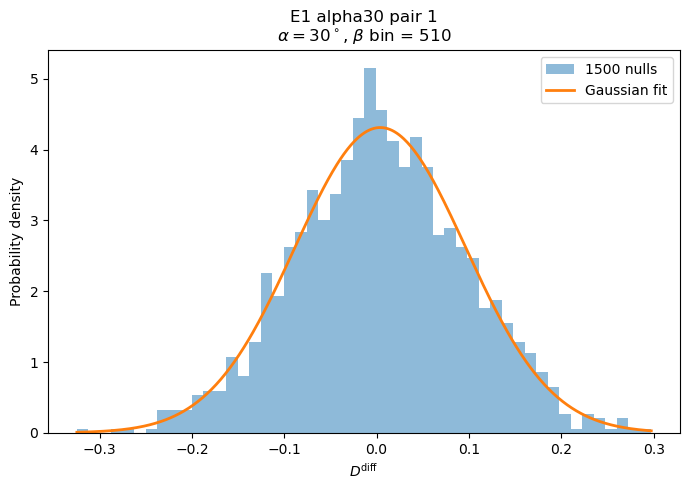

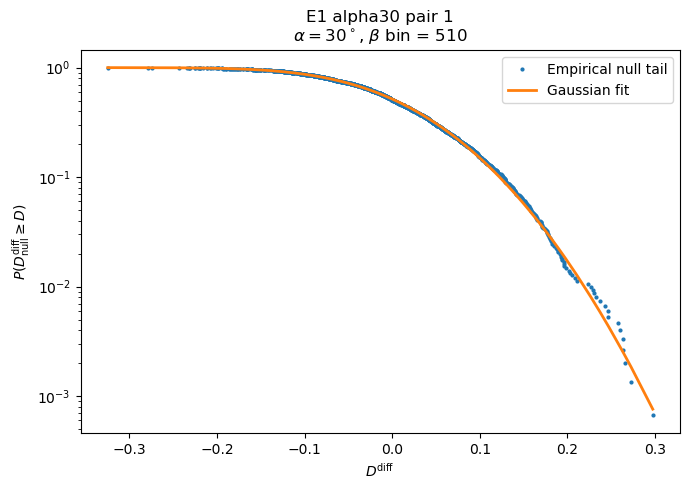


Upper-tail comparison
D_diff      p_empirical      p_gaussian
 0.126356     1.000000e-01     9.294474e-02
 0.157829     5.000000e-02     4.815664e-02
 0.182238     2.533333e-02     2.700192e-02
 0.226318     1.000000e-02     8.126011e-03
 0.246689     5.333333e-03     4.353078e-03
 0.297300     6.666667e-04     7.612038e-04


In [3]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

from scipy.stats import norm


# ============================================================
# Use the 1500 new null maps
# ============================================================

null_map_dir = root / "null_standardisation_1500"

null_files = sorted(
    null_map_dir.glob("null_r????.fits")
)

if len(null_files) != 1500:
    raise RuntimeError(
        f"Expected 1500 null maps, found {len(null_files)}."
    )

print("Null maps used:", len(null_files))


# ============================================================
# Rebuild null D_diff(beta) curves
#
# IMPORTANT:
# These are recomputed from the 1500 null maps.
# Do NOT reuse the previous 100-null null_curves.
# ============================================================

null_curves = {}

for geometry in geometries:
    name = geometry["name"]

    null_curves[name] = {
        "d_diff": np.full(
            (len(null_files), nphi),
            np.nan,
            dtype=float,
        ),
        "n_joint": np.zeros(
            (len(null_files), nphi),
            dtype=int,
        ),
    }


for r, null_file in enumerate(null_files):

    # Read full-sky Gaussian null map
    null_map = hp.read_map(
        null_file,
        field=0,
        dtype=np.float64,
    )

    # Apply exactly the same D filter used for the E1 maps
    filtered_null_map = apply_d_filter(
        null_map
    )

    # Evaluate exactly the same fixed geometries
    for geometry in geometries:
        name = geometry["name"]

        d_diff, n_joint = get_d_diff_curve_fft(
            filtered_null_map,
            geometry["pixel_i"],
            geometry["pixel_j"],
        )

        null_curves[name]["d_diff"][r] = d_diff
        null_curves[name]["n_joint"][r] = n_joint

    if (r + 1) % 100 == 0 or r == 0:
        print(
            f"Finished null map {r + 1}/1500"
        )


# ============================================================
# Sanity check
# ============================================================

for geometry in geometries:
    name = geometry["name"]

    print(
        name,
        null_curves[name]["d_diff"].shape,
    )


# ============================================================
# Choose one fixed (alpha, i, j, beta)
# ============================================================

name = "E1 alpha30 pair 1"
beta_bin = 510

null_d = null_curves[name]["d_diff"][:, beta_bin]

null_d = null_d[
    np.isfinite(null_d)
]


# ============================================================
# Gaussian fit
# ============================================================

mu = np.mean(null_d)

sigma = np.std(
    null_d,
    ddof=1,
)

x = np.linspace(
    null_d.min(),
    null_d.max(),
    500,
)


# ============================================================
# Basic numerical information
# ============================================================

print()

print(
    "Geometry:",
    name,
)

print(
    "beta bin:",
    beta_bin,
)

print(
    "beta deg:",
    360.0 * beta_bin / nphi,
)

print(
    "Number of nulls:",
    len(null_d),
)

print(
    "mean =",
    mu,
)

print(
    "std =",
    sigma,
)

print(
    "min/max =",
    null_d.min(),
    null_d.max(),
)


# ============================================================
# Plot null distribution + Gaussian fit
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.hist(
    null_d,
    bins=50,
    density=True,
    alpha=0.5,
    label="1500 nulls",
)

plt.plot(
    x,
    norm.pdf(
        x,
        loc=mu,
        scale=sigma,
    ),
    linewidth=2,
    label="Gaussian fit",
)

plt.xlabel(
    r"$D^{\rm diff}$"
)

plt.ylabel(
    "Probability density"
)

plt.title(
    f"{name}\n"
    rf"$\alpha=30^\circ$, "
    rf"$\beta$ bin = {beta_bin}"
)

plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Empirical upper-tail survival function
# ============================================================

d_sorted = np.sort(
    null_d
)

n = len(
    d_sorted
)


# Empirical survival probability.
# The largest point has p = 1/N, not zero.

p_empirical = (
    n - np.arange(n)
) / n


# Gaussian survival probability

p_gaussian = norm.sf(
    d_sorted,
    loc=mu,
    scale=sigma,
)


# ============================================================
# Plot empirical tail against Gaussian tail
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.semilogy(
    d_sorted,
    p_empirical,
    ".",
    markersize=4,
    label="Empirical null tail",
)

plt.semilogy(
    d_sorted,
    p_gaussian,
    linewidth=2,
    label="Gaussian fit",
)

plt.xlabel(
    r"$D^{\rm diff}$"
)

plt.ylabel(
    r"$P(D^{\rm diff}_{\rm null} \geq D)$"
)

plt.title(
    f"{name}\n"
    rf"$\alpha=30^\circ$, "
    rf"$\beta$ bin = {beta_bin}"
)

plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Compare Gaussian and empirical tail numerically
#
# Useful especially in the upper tail.
# ============================================================

tail_indices = np.unique(
    np.clip(
        np.array(
            [
                int(0.90 * n),
                int(0.95 * n),
                int(0.975 * n),
                int(0.99 * n),
                int(0.995 * n),
                n - 1,
            ]
        ),
        0,
        n - 1,
    )
)

print()
print("Upper-tail comparison")

print(
    "D_diff      "
    "p_empirical      "
    "p_gaussian"
)

for idx in tail_indices:
    print(
        f"{d_sorted[idx]: .6f}    "
        f"{p_empirical[idx]: .6e}    "
        f"{p_gaussian[idx]: .6e}"
    )


# ============================================================
# Build mean(beta) and sigma(beta) from all 1500 nulls
#
# These are needed for the Z test.
# ============================================================

null_d_all_beta = null_curves[name]["d_diff"]

null_mean_beta = np.nanmean(
    null_d_all_beta,
    axis=0,
)

null_std_beta = np.nanstd(
    null_d_all_beta,
    axis=0,
    ddof=1,
)

## Five-fold held-out validation of the null-tail model

Using the original 1500 null realisations, we evaluate the fixed trial

$$
\alpha=30^\circ,
\qquad
\text{E1 pair 1},
\qquad
\beta_{\mathrm{bin}}=510.
$$

The corresponding $D^{\mathrm{diff}}$ values are reconstructed from the
original null maps and divided into five folds. For each fold,

$$
1200
\quad\text{nulls are used for fitting,}
$$

and

$$
300
\quad\text{nulls are held out for testing.}
$$

The Gaussian model is fitted to the full training sample. GPD tail models are
also fitted above the $90\%$, $92.5\%$, and $95\%$ training quantiles.

For the independent held-out tail values, the prediction error is

$$
\epsilon
=
\left|
\log_{10}p_{\mathrm{model}}
-
\log_{10}p_{\mathrm{empirical}}
\right|,
$$

where a smaller value means that the model predicts the unseen null survival
probability more accurately.

The comparison is repeated over all five folds, and we record the mean error
of each tail model, the corresponding Gaussian error on the same held-out
points, and the number of folds in which the alternative model performs better
than the Gaussian.

In [12]:
import numpy as np

from scipy.stats import genpareto, norm


# ============================================================
# Fixed null sample
#
# E1 alpha = 30 deg, pair 1
# beta_bin = 510
#
# One D_diff value from each of the original 1500 null maps.
# ============================================================

name = "E1 alpha30 pair 1"
beta_bin = 510

null_d_all_beta = np.asarray(
    null_curves[
        name
    ][
        "d_diff"
    ],
    dtype=np.float64,
)

if null_d_all_beta.shape != (1500, 512):
    raise RuntimeError(
        "Expected null D_diff array with shape "
        f"(1500, 512), found {null_d_all_beta.shape}."
    )

null_d = null_d_all_beta[
    :,
    beta_bin,
].copy()

if null_d.shape != (1500,):
    raise RuntimeError(
        f"Expected fixed-beta shape (1500,), "
        f"found {null_d.shape}."
    )

if not np.all(
    np.isfinite(null_d)
):
    bad_indices = np.flatnonzero(
        ~np.isfinite(null_d)
    )

    raise RuntimeError(
        "The fixed-beta sample contains non-finite "
        f"values at indices {bad_indices.tolist()}."
    )

print(
    "Geometry:",
    name,
)

print(
    "beta_bin:",
    beta_bin,
)

print(
    "null_d shape:",
    null_d.shape,
)

print(
    "finite values:",
    np.count_nonzero(
        np.isfinite(null_d)
    ),
)


# ============================================================
# Five-fold held-out test
#
# 1500 = 5 x 300
#
# Each fold:
#
#     1200 training nulls
#      300 independent held-out nulls
#
# Use five fixed contiguous batches.
# ============================================================

N_FOLDS = 5
N_PER_FOLD = 300

indices = np.arange(
    len(null_d)
)

folds = np.array_split(
    indices,
    N_FOLDS,
)

if any(
    len(fold) != N_PER_FOLD
    for fold in folds
):
    raise RuntimeError(
        "Expected five folds containing exactly "
        "300 null values each."
    )

print()

for fold_index, fold in enumerate(
    folds,
    start=1,
):
    print(
        f"Fold {fold_index}: "
        f"indices {fold[0]}-{fold[-1]} "
        f"({len(fold)} values)"
    )


# ============================================================
# GPD thresholds
# ============================================================

GPD_QUANTILES = [
    0.90,
    0.925,
    0.95,
]


# ============================================================
# Storage
# ============================================================

gpd_errors = {
    q: []
    for q in GPD_QUANTILES
}

gpd_gaussian_errors = {
    q: []
    for q in GPD_QUANTILES
}

gpd_wins = {
    q: 0
    for q in GPD_QUANTILES
}

gpd_tail_counts = {
    q: []
    for q in GPD_QUANTILES
}


# ============================================================
# Five held-out folds
# ============================================================

for fold_index in range(
    N_FOLDS
):

    test_idx = folds[
        fold_index
    ]

    train_idx = np.concatenate(
        [
            folds[j]
            for j in range(N_FOLDS)
            if j != fold_index
        ]
    )

    d_train = null_d[
        train_idx
    ]

    d_test = null_d[
        test_idx
    ]

    if len(d_train) != 1200:
        raise RuntimeError(
            f"Fold {fold_index + 1}: "
            f"expected 1200 training values, "
            f"found {len(d_train)}."
        )

    if len(d_test) != 300:
        raise RuntimeError(
            f"Fold {fold_index + 1}: "
            f"expected 300 test values, "
            f"found {len(d_test)}."
        )


    # --------------------------------------------------------
    # Gaussian fit to all 1200 training values
    # --------------------------------------------------------

    mu_gaussian, sigma_gaussian = norm.fit(
        d_train
    )

    if (
        not np.isfinite(mu_gaussian)
        or not np.isfinite(sigma_gaussian)
        or sigma_gaussian <= 0.0
    ):
        raise RuntimeError(
            f"Fold {fold_index + 1}: "
            "invalid Gaussian fit."
        )


    # --------------------------------------------------------
    # Empirical survival probabilities from the
    # independent 300-value test sample
    #
    # Sorted in ascending D:
    #
    #     smallest -> p = 1
    #     largest  -> p = 1 / 300
    # --------------------------------------------------------

    d_test_sorted = np.sort(
        d_test
    )

    n_test = len(
        d_test_sorted
    )

    p_empirical_all = (
        n_test
        - np.arange(
            n_test,
            dtype=np.float64,
        )
    ) / n_test


    # ========================================================
    # GPD tail fits
    # ========================================================

    for q in GPD_QUANTILES:

        # ----------------------------------------------------
        # Tail threshold from training values only
        # ----------------------------------------------------

        u = float(
            np.quantile(
                d_train,
                q,
            )
        )

        training_tail = (
            d_train > u
        )

        exceedances = (
            d_train[
                training_tail
            ]
            - u
        )

        n_exceed = len(
            exceedances
        )

        if n_exceed < 3:
            raise RuntimeError(
                f"Fold {fold_index + 1}, q={q}: "
                "too few training exceedances."
            )

        # Probability of entering the tail, measured
        # directly from the training sample.
        p_u = float(
            np.mean(
                training_tail
            )
        )


        # ----------------------------------------------------
        # Fit GPD to training exceedances
        # ----------------------------------------------------

        xi, _, scale = genpareto.fit(
            exceedances,
            floc=0.0,
        )

        if (
            not np.isfinite(xi)
            or not np.isfinite(scale)
            or scale <= 0.0
        ):
            raise RuntimeError(
                f"Fold {fold_index + 1}, q={q}: "
                "invalid GPD fit."
            )


        # ----------------------------------------------------
        # Evaluate both models on exactly the same
        # independent held-out tail values
        # ----------------------------------------------------

        use_test = (
            d_test_sorted >= u
        )

        d_tail = d_test_sorted[
            use_test
        ]

        p_empirical = p_empirical_all[
            use_test
        ]

        gpd_tail_counts[
            q
        ].append(
            len(d_tail)
        )

        if len(d_tail) == 0:
            raise RuntimeError(
                f"Fold {fold_index + 1}, q={q}: "
                "no held-out values above the "
                "training threshold."
            )


        # ----------------------------------------------------
        # Gaussian prediction
        # ----------------------------------------------------

        p_gaussian = norm.sf(
            d_tail,
            loc=mu_gaussian,
            scale=sigma_gaussian,
        )


        # ----------------------------------------------------
        # GPD prediction
        #
        # P(D >= d)
        # =
        # P(D > u)
        # x
        # P(D-u >= d-u | D > u)
        # ----------------------------------------------------

        p_gpd = (
            p_u
            * genpareto.sf(
                d_tail - u,
                c=xi,
                loc=0.0,
                scale=scale,
            )
        )


        # ----------------------------------------------------
        # Compare prediction error in log10 survival
        # probability
        # ----------------------------------------------------

        valid = (
            np.isfinite(p_empirical)
            & np.isfinite(p_gaussian)
            & np.isfinite(p_gpd)
            & (p_empirical > 0.0)
            & (p_gaussian > 0.0)
            & (p_gpd > 0.0)
        )

        if not np.any(valid):
            raise RuntimeError(
                f"Fold {fold_index + 1}, q={q}: "
                "no valid tail probabilities."
            )

        gaussian_error = float(
            np.mean(
                np.abs(
                    np.log10(
                        p_gaussian[
                            valid
                        ]
                    )
                    - np.log10(
                        p_empirical[
                            valid
                        ]
                    )
                )
            )
        )

        gpd_error = float(
            np.mean(
                np.abs(
                    np.log10(
                        p_gpd[
                            valid
                        ]
                    )
                    - np.log10(
                        p_empirical[
                            valid
                        ]
                    )
                )
            )
        )

        gpd_gaussian_errors[
            q
        ].append(
            gaussian_error
        )

        gpd_errors[
            q
        ].append(
            gpd_error
        )

        if gpd_error < gaussian_error:
            gpd_wins[q] += 1


# ============================================================
# Per-fold results
# ============================================================

print()
print(
    "===== Per-fold held-out results ====="
)

for q in GPD_QUANTILES:

    print()
    print(
        f"GPD threshold = {100.0 * q:.1f}%"
    )

    for fold_index in range(
        N_FOLDS
    ):
        print(
            f"  Fold {fold_index + 1}: "
            f"N_test_tail="
            f"{gpd_tail_counts[q][fold_index]:3d}, "
            f"GPD error="
            f"{gpd_errors[q][fold_index]:.4f}, "
            f"Gaussian error="
            f"{gpd_gaussian_errors[q][fold_index]:.4f}"
        )


# ============================================================
# Final summary
# ============================================================

print()
print(
    "===== 5-fold held-out Gaussian vs GPD test ====="
)
print()

print(
    "Model           "
    "Mean GPD error   "
    "Mean Gaussian error   "
    "Folds GPD better"
)

for q in GPD_QUANTILES:

    print(
        f"GPD u={100.0 * q:4.1f}%   "
        f"{np.mean(gpd_errors[q]):.4f}           "
        f"{np.mean(gpd_gaussian_errors[q]):.4f}                "
        f"{gpd_wins[q]}/5"
    )

Geometry: E1 alpha30 pair 1
beta_bin: 510
null_d shape: (1500,)
finite values: 1500

Fold 1: indices 0-299 (300 values)
Fold 2: indices 300-599 (300 values)
Fold 3: indices 600-899 (300 values)
Fold 4: indices 900-1199 (300 values)
Fold 5: indices 1200-1499 (300 values)

===== Per-fold held-out results =====

GPD threshold = 90.0%
  Fold 1: N_test_tail= 31, GPD error=0.1516, Gaussian error=0.1308
  Fold 2: N_test_tail= 25, GPD error=0.0684, Gaussian error=0.0670
  Fold 3: N_test_tail= 31, GPD error=0.0935, Gaussian error=0.0924
  Fold 4: N_test_tail= 33, GPD error=0.0422, Gaussian error=0.0500
  Fold 5: N_test_tail= 26, GPD error=0.0854, Gaussian error=0.0726

GPD threshold = 92.5%
  Fold 1: N_test_tail= 27, GPD error=0.1754, Gaussian error=0.1406
  Fold 2: N_test_tail= 22, GPD error=0.0800, Gaussian error=0.0735
  Fold 3: N_test_tail= 23, GPD error=0.1208, Gaussian error=0.1122
  Fold 4: N_test_tail= 22, GPD error=0.0435, Gaussian error=0.0423
  Fold 5: N_test_tail= 20, GPD error=0.09

## Circular consensus of the individual-$s$ statistics

For each separation $s$, define its preferred phase shift as

$$
\beta_s
=
\operatorname*{arg\,max}_{\beta}
D_s(\beta).
$$

The circular distance between two phase bins is

$$
d_{\mathrm{circ}}(\beta_a,\beta_b)
=
\min\left(
|\beta_a-\beta_b|,
N_\phi-|\beta_a-\beta_b|
\right).
$$

### Circular consensus

The consensus phase is chosen from the set of preferred phases $\{\beta_s\}$ by minimising

$$
\beta_{\mathrm{cons}}
=
\operatorname*{arg\,min}_{\beta\in\{\beta_s\}}
\sum_s
d_{\mathrm{circ}}(\beta,\beta_s).
$$

If tied, the candidate with the most exact votes is chosen; if still tied, the one with the larger $\sum_s D_s(\beta)$ is used.

### Null-weighted circular consensus

For each separation,

$$
D_{s,\max}^{\mathrm{E1}}
=
\max_{\beta}D_s^{\mathrm{E1}}(\beta).
$$

Let $R_s$ be the number of null realisations whose corresponding maximum satisfies

$$
D_{s,\max}^{\mathrm{null}}
\ge
D_{s,\max}^{\mathrm{E1}},
$$

out of $M_s$ usable null realisations. The empirical null survival probability is

$$
\widehat{S}_s
=
P\!\left(
D_{s,\max}^{\mathrm{null}}
\ge
D_{s,\max}^{\mathrm{E1}}
\right)
\approx
\frac{R_s}{M_s}.
$$
and the weight

$$
w_s
=
-\log_{10}p_s.
$$

The weighted consensus is then

$$
\beta_{\mathrm{wcons}}
=
\operatorname*{arg\,min}_{\beta\in\{\beta_s\}}
\sum_s
w_s\,
d_{\mathrm{circ}}(\beta,\beta_s).
$$

The known value $\beta=510$ is used only afterwards as a recovery check, not in either consensus selection.

In [4]:
import healpy as hp
import numpy as np
import pandas as pd

from IPython.display import display


# ============================================================
# Individual-s D curves
# s = 1,...,d_diff_max_separation
# ============================================================

def get_individual_d_curves_fft(
    sky_map,
    pixel_i,
    pixel_j,
):

    ring_i, valid_i = sample_circle(
        sky_map,
        pixel_i,
        alpha_deg,
    )

    ring_j, valid_j = sample_circle(
        sky_map,
        pixel_j,
        alpha_deg,
    )

    d_by_s = np.full(
        (
            d_diff_max_separation,
            nphi,
        ),
        np.nan,
        dtype=np.float64,
    )

    for s_index, separation_bin in enumerate(
        range(
            1,
            d_diff_max_separation + 1,
        )
    ):

        delta_t_i = (
            np.roll(
                ring_i,
                -separation_bin,
            )
            - ring_i
        )

        valid_delta_i = (
            valid_i
            & np.roll(
                valid_i,
                -separation_bin,
            )
        )

        if orientable:

            delta_t_j = (
                np.roll(
                    ring_j,
                    separation_bin,
                )
                - ring_j
            )

            valid_delta_j = (
                valid_j
                & np.roll(
                    valid_j,
                    separation_bin,
                )
            )

        else:

            delta_t_j = (
                np.roll(
                    ring_j,
                    -separation_bin,
                )
                - ring_j
            )

            valid_delta_j = (
                valid_j
                & np.roll(
                    valid_j,
                    -separation_bin,
                )
            )

        w_i = valid_delta_i.astype(
            np.float64
        )

        w_j = valid_delta_j.astype(
            np.float64
        )

        fw_i = np.fft.fft(
            w_i
        )

        fw_j = np.fft.fft(
            w_j
        )

        fx_i = np.fft.fft(
            w_i * delta_t_i
        )

        fx_j = np.fft.fft(
            w_j * delta_t_j
        )

        fe_i = np.fft.fft(
            w_i * delta_t_i**2
        )

        fe_j = np.fft.fft(
            w_j * delta_t_j**2
        )

        if not orientable:

            fw_i = np.conj(
                fw_i
            )

            fx_i = np.conj(
                fx_i
            )

            fe_i = np.conj(
                fe_i
            )

        numerator = (
            2.0
            * np.fft.ifft(
                fx_i * fx_j
            ).real
        )

        denominator = np.fft.ifft(
            fe_i * fw_j
            + fw_i * fe_j
        ).real

        n_joint = np.rint(
            np.fft.ifft(
                fw_i * fw_j
            ).real
        ).astype(int)

        n_joint = np.clip(
            n_joint,
            0,
            nphi,
        )

        usable = (
            (
                n_joint
                >= d_min_joint_samples
            )
            &
            (
                denominator
                > np.finfo(float).tiny
            )
        )

        d_by_s[
            s_index,
            usable,
        ] = np.clip(
            numerator[usable]
            / denominator[usable],
            -1.0,
            1.0,
        )

    return d_by_s


# ============================================================
# Circular distance
# ============================================================

def circular_distance(
    beta_a,
    beta_b,
):

    d = np.abs(
        beta_a - beta_b
    )

    return np.minimum(
        d,
        nphi - d,
    )


# ============================================================
# Ordinary circular consensus
# ============================================================

def circular_consensus(
    beta_s,
    d_by_s,
):

    beta_s = np.asarray(
        beta_s,
        dtype=int,
    )

    candidates = np.unique(
        beta_s
    )

    total_distance = np.array(
        [
            np.sum(
                circular_distance(
                    candidate,
                    beta_s,
                )
            )
            for candidate in candidates
        ],
        dtype=np.float64,
    )

    # 1. Minimum total circular distance
    best_distance = np.min(
        total_distance
    )

    best = candidates[
        np.isclose(
            total_distance,
            best_distance,
        )
    ]

    # 2. If tied, largest number of exact votes
    if len(best) > 1:

        votes = np.array(
            [
                np.count_nonzero(
                    beta_s
                    == candidate
                )
                for candidate in best
            ],
            dtype=int,
        )

        best = best[
            votes
            == np.max(votes)
        ]

    # 3. If still tied, larger total D_s
    if len(best) > 1:

        strengths = np.array(
            [
                np.nansum(
                    d_by_s[
                        :,
                        candidate,
                    ]
                )
                for candidate in best
            ],
            dtype=np.float64,
        )

        best = best[
            np.isclose(
                strengths,
                np.max(strengths),
            )
        ]

    return int(
        best[0]
    )


# ============================================================
# Null-weighted circular consensus
# ============================================================

def weighted_circular_consensus(
    beta_s,
    weights,
    d_by_s,
):

    beta_s = np.asarray(
        beta_s,
        dtype=int,
    )

    weights = np.asarray(
        weights,
        dtype=np.float64,
    )

    candidates = np.unique(
        beta_s
    )

    total_distance = np.array(
        [
            np.sum(
                weights
                * circular_distance(
                    candidate,
                    beta_s,
                )
            )
            for candidate in candidates
        ],
        dtype=np.float64,
    )

    # 1. Minimum weighted circular distance
    best_distance = np.min(
        total_distance
    )

    best = candidates[
        np.isclose(
            total_distance,
            best_distance,
        )
    ]

    # 2. If tied, largest exact-vote weight
    if len(best) > 1:

        weighted_votes = np.array(
            [
                np.sum(
                    weights[
                        beta_s
                        == candidate
                    ]
                )
                for candidate in best
            ],
            dtype=np.float64,
        )

        best = best[
            np.isclose(
                weighted_votes,
                np.max(
                    weighted_votes
                ),
            )
        ]

    # 3. If still tied, larger total D_s
    if len(best) > 1:

        strengths = np.array(
            [
                np.nansum(
                    d_by_s[
                        :,
                        candidate,
                    ]
                )
                for candidate in best
            ],
            dtype=np.float64,
        )

        best = best[
            np.isclose(
                strengths,
                np.max(strengths),
            )
        ]

    return int(
        best[0]
    )


# ============================================================
# Real E1 geometries only
# ============================================================

real_geometries = [
    geometry
    for geometry in geometries
    if geometry["name"] != "Control"
]


# ============================================================
# Build null distributions of max_beta D_s
#
# We only need max_beta D_s for the weighting.
# There is no need to store all (1500, s, beta) curves.
# ============================================================

null_max_by_s = {
    geometry["name"]: np.full(
        (
            len(null_files),
            d_diff_max_separation,
        ),
        np.nan,
        dtype=np.float64,
    )
    for geometry in real_geometries
}


for r, null_file in enumerate(
    null_files
):

    null_map = hp.read_map(
        null_file,
        field=0,
        dtype=np.float64,
    )

    filtered_null_map = apply_d_filter(
        null_map
    )

    for geometry in real_geometries:

        name = geometry["name"]

        null_d_by_s = (
            get_individual_d_curves_fft(
                filtered_null_map,
                geometry["pixel_i"],
                geometry["pixel_j"],
            )
        )

        null_max_by_s[
            name
        ][r] = np.nanmax(
            null_d_by_s,
            axis=1,
        )

    if (
        (r + 1) % 100 == 0
        or r == 0
    ):

        print(
            f"Finished null map "
            f"{r + 1}/{len(null_files)}"
        )


# ============================================================
# E1:
# individual beta_s
# ordinary circular consensus
# null-weighted circular consensus
# ============================================================

rows = []


for r, e1_file in enumerate(
    e1_files
):

    rr = f"{r:03d}"

    # These E1 files are already D-filtered.
    e1_map = hp.read_map(
        e1_file,
        field=0,
        dtype=np.float64,
    )

    for geometry in real_geometries:

        name = geometry["name"]

        # ----------------------------------------------------
        # Calculate each individual D_s(beta)
        # shape = (number of s, 512)
        # ----------------------------------------------------

        d_by_s = (
            get_individual_d_curves_fft(
                e1_map,
                geometry["pixel_i"],
                geometry["pixel_j"],
            )
        )

        # ----------------------------------------------------
        # Preferred beta for every individual s
        # ----------------------------------------------------

        beta_s = np.array(
            [
                int(
                    np.nanargmax(
                        d_by_s[
                            s_index
                        ]
                    )
                )
                for s_index in range(
                    d_diff_max_separation
                )
            ],
            dtype=int,
        )

        # ----------------------------------------------------
        # Ordinary circular consensus
        # ----------------------------------------------------

        beta_consensus = (
            circular_consensus(
                beta_s,
                d_by_s,
            )
        )

        # ----------------------------------------------------
        # Null-derived reliability weight for each s
        #
        # p_s = (1 + R_s) / (1 + M)
        # w_s = -log10(p_s)
        # ----------------------------------------------------

        weights = np.zeros(
            d_diff_max_separation,
            dtype=np.float64,
        )

        for s_index in range(
            d_diff_max_separation
        ):

            e1_max = np.nanmax(
                d_by_s[
                    s_index
                ]
            )

            null_max = (
                null_max_by_s[
                    name
                ][
                    :,
                    s_index,
                ]
            )

            null_max = null_max[
                np.isfinite(
                    null_max
                )
            ]

            m = len(
                null_max
            )

            if m == 0:
                continue

            r_null = np.count_nonzero(
                null_max
                >= e1_max
            )

            p_s = (
                1.0 + r_null
            ) / (
                1.0 + m
            )

            weights[
                s_index
            ] = (
                -np.log10(
                    p_s
                )
            )

        # ----------------------------------------------------
        # Weighted circular consensus
        # ----------------------------------------------------

        beta_weighted_consensus = (
            weighted_circular_consensus(
                beta_s,
                weights,
                d_by_s,
            )
        )

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        row = {
            "Realisation":
                f"r{rr}",

            "Geometry":
                name,
        }

        for s in range(
            1,
            d_diff_max_separation + 1,
        ):

            row[
                f"beta_s{s}"
            ] = beta_s[
                s - 1
            ]

            row[
                f"w_s{s}"
            ] = weights[
                s - 1
            ]

        row[
            "beta_consensus"
        ] = beta_consensus

        row[
            "beta_weighted_consensus"
        ] = beta_weighted_consensus

        rows.append(
            row
        )

    print(
        f"Finished E1 r{rr}"
    )


# ============================================================
# Results
# ============================================================

consensus_table = pd.DataFrame(
    rows
)


# ============================================================
# Post-hoc beta=510 recovery
# ============================================================

n_consensus_correct = np.count_nonzero(
    consensus_table[
        "beta_consensus"
    ].to_numpy()
    == 510
)

n_weighted_correct = np.count_nonzero(
    consensus_table[
        "beta_weighted_consensus"
    ].to_numpy()
    == 510
)


print(
    "\n===== circular-consensus recovery ====="
)

print(
    f"circular consensus: "
    f"{n_consensus_correct}/40"
)


print(
    "\n===== weighted circular-consensus recovery ====="
)

print(
    f"weighted circular consensus: "
    f"{n_weighted_correct}/40"
)


# ============================================================
# Circular-consensus failures
# ============================================================

consensus_failures = consensus_table[
    consensus_table[
        "beta_consensus"
    ]
    != 510
]


consensus_failure_columns = [
    "Realisation",
    "Geometry",
] + [
    f"beta_s{s}"
    for s in range(
        1,
        d_diff_max_separation + 1,
    )
] + [
    "beta_consensus",
]


print(
    "\n===== circular-consensus failures ====="
)

display(
    consensus_failures[
        consensus_failure_columns
    ].round(
        4
    )
)


# ============================================================
# Weighted circular-consensus failures
# ============================================================

weighted_failures = consensus_table[
    consensus_table[
        "beta_weighted_consensus"
    ]
    != 510
]


weighted_failure_columns = [
    "Realisation",
    "Geometry",
] + [
    f"beta_s{s}"
    for s in range(
        1,
        d_diff_max_separation + 1,
    )
] + [
    f"w_s{s}"
    for s in range(
        1,
        d_diff_max_separation + 1,
    )
] + [
    "beta_weighted_consensus",
]


print(
    "\n===== weighted-consensus failures ====="
)

display(
    weighted_failures[
        weighted_failure_columns
    ].round(
        4
    )
)


Finished null map 1/1500
Finished null map 100/1500
Finished null map 200/1500
Finished null map 300/1500
Finished null map 400/1500
Finished null map 500/1500
Finished null map 600/1500
Finished null map 700/1500
Finished null map 800/1500
Finished null map 900/1500
Finished null map 1000/1500
Finished null map 1100/1500
Finished null map 1200/1500
Finished null map 1300/1500
Finished null map 1400/1500
Finished null map 1500/1500
Finished E1 r000
Finished E1 r001
Finished E1 r002
Finished E1 r003
Finished E1 r004
Finished E1 r005
Finished E1 r006
Finished E1 r007
Finished E1 r008
Finished E1 r009

===== circular-consensus recovery =====
circular consensus: 38/40

===== weighted circular-consensus recovery =====
weighted circular consensus: 38/40

===== circular-consensus failures =====


,Realisation,Geometry,beta_s1,beta_s2,beta_s3,beta_s4,beta_s5,beta_s6,beta_s7,beta_s8,beta_consensus
3,r000,E1 alpha30 pair 4,36,510,510,5,5,28,16,16,5
27,r006,E1 alpha30 pair 4,120,120,115,121,326,56,56,56,120



===== weighted-consensus failures =====


,Realisation,Geometry,beta_s1,beta_s2,beta_s3,beta_s4,beta_s5,beta_s6,beta_s7,beta_s8,w_s1,w_s2,w_s3,w_s4,w_s5,w_s6,w_s7,w_s8,beta_weighted_consensus
3,r000,E1 alpha30 pair 4,36,510,510,5,5,28,16,16,0.7581,1.5531,0.8072,1.2956,1.0003,0.0545,0.2434,0.2793,5
27,r006,E1 alpha30 pair 4,120,120,115,121,326,56,56,56,1.1470,0.5409,0.3363,0.2169,0.1119,0.6726,0.5369,0.1195,120


## Blind candidate-pair comparison

For each E1 realisation at fixed opening angle

$$
\alpha = 30^\circ,
$$

the four known true circle pairs are tested together with 100 randomly selected
wrong near-antipodal pairs satisfying

$$
\theta_{ij} \ge 179^\circ.
$$

The wrong pairs are selected before examining the E1 maps, giving 104
candidate pairs in total.

For each candidate, we use the previously defined combined
$D^{\mathrm{diff}}(\beta)$, conditional $Q(\beta)$, circular-consensus
phase, and null-weighted circular-consensus phase.

Each candidate first selects its own preferred $\beta$. The 104 candidates
then compete using six choices:

1. max-$\beta$ combined $D^{\mathrm{diff}}$
2. max-$\beta$ conditional $Q$
3. circular-consensus $\beta$ evaluated with combined $D^{\mathrm{diff}}$
4. circular-consensus $\beta$ evaluated with conditional $Q$
5. weighted-consensus $\beta$ evaluated with combined $D^{\mathrm{diff}}$
6. weighted-consensus $\beta$ evaluated with conditional $Q$

The test records whether the highest-scoring candidate is one of the four
true E1 pairs. The known phase $\beta=510$ is used only afterwards to check
exact pair-and-phase recovery.

In [7]:
from pathlib import Path
import healpy as hp
import numpy as np
import pandas as pd
from scipy.stats import norm
from IPython.display import display


# ==================================================
# Settings
# ==================================================

root = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

src = root / "src"


e1_files = [
    src / f"E1_fgres_filter_r{r:03d}.fits"
    for r in range(10)
]


null_map_dir = (
    root
    / "null_standardisation_1500"
)

null_files = sorted(
    null_map_dir.glob(
        "null_r????.fits"
    )
)

if len(null_files) != 1500:
    raise RuntimeError(
        f"Expected 1500 null maps, "
        f"found {len(null_files)}."
    )


mask_file = (
    src
    / "COM_Mask_CMB-common-Mask-Int_128_R3.00.fits"
)

filter_file = (
    root
    / "SW_Doppler_ISW_filter_lmax300.dat"
)


nside = 128
nside_search = 128

nphi = 512
m_min = 2

alpha_deg = 30.0

mask_threshold = 0.5
d_min_joint_samples = 34
d_filter_lmax = 300

d_diff_max_separation = 8

orientable = True

min_separation_angle = 179.0

n_tail_fit = 20


# Number of WRONG competitors
N_WRONG = 100

# Fixed so every rerun uses the same wrong pairs
RNG_SEED = 20260917


print(
    "Null maps:",
    len(null_files),
)


# ==================================================
# Four true E1 pairs
# ==================================================

true_geometries = [
    {
        "name": "E1 pair 1",
        "theta_i": 54.68,
        "phi_i": 225.00,
        "theta_j": 125.32,
        "phi_j": 45.00,
        "is_true": True,
    },
    {
        "name": "E1 pair 2",
        "theta_i": 54.68,
        "phi_i": 45.00,
        "theta_j": 125.32,
        "phi_j": 225.00,
        "is_true": True,
    },
    {
        "name": "E1 pair 3",
        "theta_i": 54.68,
        "phi_i": 135.00,
        "theta_j": 125.32,
        "phi_j": 315.00,
        "is_true": True,
    },
    {
        "name": "E1 pair 4",
        "theta_i": 125.32,
        "phi_i": 135.00,
        "theta_j": 54.68,
        "phi_j": 315.00,
        "is_true": True,
    },
]


# ==================================================
# Convert true centres to NSIDE=128 search pixels
# ==================================================

for geometry in true_geometries:

    geometry["pixel_i"] = hp.ang2pix(
        nside_search,
        np.deg2rad(
            geometry["theta_i"]
        ),
        np.deg2rad(
            geometry["phi_i"]
        ),
    )

    geometry["pixel_j"] = hp.ang2pix(
        nside_search,
        np.deg2rad(
            geometry["theta_j"]
        ),
        np.deg2rad(
            geometry["phi_j"]
        ),
    )


# ==================================================
# Draw 100 random WRONG near-antipodal pairs
#
# Same search-grid condition:
#
# separation >= 179 degrees.
#
# These are selected BEFORE looking at any E1 map.
# ==================================================

rng = np.random.default_rng(
    RNG_SEED
)

npix_search = hp.nside2npix(
    nside_search
)

antipode_radius = np.deg2rad(
    180.0
    - min_separation_angle
)


true_keys = {
    tuple(
        sorted(
            (
                int(g["pixel_i"]),
                int(g["pixel_j"]),
            )
        )
    )
    for g in true_geometries
}


wrong_geometries = []

wrong_keys = set()


while len(
    wrong_geometries
) < N_WRONG:

    pixel_i = int(
        rng.integers(
            0,
            npix_search,
        )
    )

    vec_i = np.asarray(
        hp.pix2vec(
            nside_search,
            pixel_i,
        ),
        dtype=np.float64,
    )

    # Search around the antipode of i
    candidate_j = hp.query_disc(
        nside_search,
        -vec_i,
        antipode_radius,
        inclusive=True,
        nest=False,
    )

    if len(
        candidate_j
    ) == 0:
        continue

    pixel_j = int(
        rng.choice(
            candidate_j
        )
    )

    if pixel_i == pixel_j:
        continue


    # Exact centre separation
    vec_j = np.asarray(
        hp.pix2vec(
            nside_search,
            pixel_j,
        ),
        dtype=np.float64,
    )

    separation_deg = np.rad2deg(
        np.arccos(
            np.clip(
                np.dot(
                    vec_i,
                    vec_j,
                ),
                -1.0,
                1.0,
            )
        )
    )

    if (
        separation_deg
        < min_separation_angle
    ):
        continue


    key = tuple(
        sorted(
            (
                pixel_i,
                pixel_j,
            )
        )
    )

    if key in true_keys:
        continue

    if key in wrong_keys:
        continue


    wrong_keys.add(
        key
    )

    wrong_geometries.append(
        {
            "name":
                (
                    f"wrong "
                    f"{len(wrong_geometries):03d}"
                ),

            "pixel_i":
                pixel_i,

            "pixel_j":
                pixel_j,

            "separation_deg":
                separation_deg,

            "is_true":
                False,
        }
    )


# ==================================================
# All candidates
#
# First 4 = true
# Remaining 100 = wrong
# ==================================================

candidates = (
    true_geometries
    + wrong_geometries
)

n_candidates = len(
    candidates
)


print(
    "\nCandidates:",
    n_candidates,
)

print(
    "True:",
    len(true_geometries),
)

print(
    "Wrong:",
    len(wrong_geometries),
)

print(
    "Wrong-pair separation range:",
    min(
        g["separation_deg"]
        for g in wrong_geometries
    ),
    "to",
    max(
        g["separation_deg"]
        for g in wrong_geometries
    ),
)


# ==================================================
# Read mask
# ==================================================

obs_mask = hp.read_map(
    mask_file,
    field=0,
    dtype=np.float64,
)


# ==================================================
# Read SW filter
# ==================================================

filter_table = np.loadtxt(
    filter_file,
    comments="#",
)

d_filter = np.zeros(
    d_filter_lmax + 1,
    dtype=np.float64,
)

filter_ell = (
    filter_table[:, 0]
    .astype(int)
)

filter_value = (
    filter_table[:, 1]
)

inside = (
    (filter_ell >= 0)
    &
    (
        filter_ell
        <= d_filter_lmax
    )
)

d_filter[
    filter_ell[
        inside
    ]
] = filter_value[
    inside
]


# ==================================================
# SW filter
# ==================================================

def apply_d_filter(
    input_map,
):

    alm = hp.map2alm(
        input_map,
        lmax=d_filter_lmax,
    )

    filtered_alm = hp.almxfl(
        alm,
        d_filter,
    )

    return hp.alm2map(
        filtered_alm,
        nside=nside,
        lmax=d_filter_lmax,
    )


# ==================================================
# Sample one circle
# ==================================================

def sample_circle(
    sky_map,
    pixel,
    alpha_deg,
):

    theta, phi = hp.pix2ang(
        nside,
        pixel,
    )

    alpha = np.deg2rad(
        alpha_deg
    )

    rotation_matrix = np.array(
        [
            [
                np.cos(theta)
                * np.cos(phi),

                -np.sin(phi),

                np.sin(theta)
                * np.cos(phi),
            ],
            [
                np.cos(theta)
                * np.sin(phi),

                np.cos(phi),

                np.sin(theta)
                * np.sin(phi),
            ],
            [
                -np.sin(theta),
                0.0,
                np.cos(theta),
            ],
        ]
    )

    phi_ring = (
        2.0
        * np.pi
        * np.arange(
            1,
            nphi + 1,
        )
        / nphi
    )

    local_vectors = np.vstack(
        [
            np.sin(alpha)
            * np.cos(phi_ring),

            np.sin(alpha)
            * np.sin(phi_ring),

            np.full(
                nphi,
                np.cos(alpha),
            ),
        ]
    )

    sky_vectors = (
        rotation_matrix
        @ local_vectors
    )

    theta_ring = np.arccos(
        np.clip(
            sky_vectors[2],
            -1.0,
            1.0,
        )
    )

    phi_ring_sky = (
        np.arctan2(
            sky_vectors[1],
            sky_vectors[0],
        )
        + np.pi
    )

    ring_pixels = hp.ang2pix(
        nside,
        theta_ring,
        phi_ring_sky,
    )

    temperature = (
        sky_map[
            ring_pixels
        ]
    )

    valid = (
        obs_mask[
            ring_pixels
        ]
        >= mask_threshold
    )

    modes = np.fft.rfft(
        temperature
    )

    modes[:m_min] = 0.0

    temperature = np.fft.irfft(
        modes,
        n=nphi,
    )

    return (
        temperature,
        valid,
    )


# ==================================================
# Combined D_diff(beta), s = 1,...,8,
# plus the 8 individual D_s(beta) curves.
#
# The combined statistic sums raw numerators and
# denominators over s and divides ONCE.
# ==================================================

def get_d_diff_curve_fft(
    sky_map,
    pixel_i,
    pixel_j,
):

    ring_i, valid_i = sample_circle(
        sky_map,
        pixel_i,
        alpha_deg,
    )

    ring_j, valid_j = sample_circle(
        sky_map,
        pixel_j,
        alpha_deg,
    )


    numerator_total = np.zeros(
        nphi,
        dtype=np.float64,
    )

    denominator_total = np.zeros(
        nphi,
        dtype=np.float64,
    )

    n_joint = np.full(
        nphi,
        nphi,
        dtype=int,
    )


    # Individual D_s(beta), s = 1,...,8
    d_by_s = np.full(
        (
            d_diff_max_separation,
            nphi,
        ),
        np.nan,
        dtype=np.float64,
    )


    for separation_bin in range(
        1,
        d_diff_max_separation + 1,
    ):

        delta_t_i = (
            np.roll(
                ring_i,
                -separation_bin,
            )
            - ring_i
        )

        valid_delta_i = (
            valid_i
            &
            np.roll(
                valid_i,
                -separation_bin,
            )
        )


        if orientable:

            delta_t_j = (
                np.roll(
                    ring_j,
                    separation_bin,
                )
                - ring_j
            )

            valid_delta_j = (
                valid_j
                &
                np.roll(
                    valid_j,
                    separation_bin,
                )
            )

        else:

            delta_t_j = (
                np.roll(
                    ring_j,
                    -separation_bin,
                )
                - ring_j
            )

            valid_delta_j = (
                valid_j
                &
                np.roll(
                    valid_j,
                    -separation_bin,
                )
            )


        w_i = valid_delta_i.astype(
            np.float64
        )

        w_j = valid_delta_j.astype(
            np.float64
        )


        fw_i = np.fft.fft(
            w_i
        )

        fw_j = np.fft.fft(
            w_j
        )

        fx_i = np.fft.fft(
            w_i
            * delta_t_i
        )

        fx_j = np.fft.fft(
            w_j
            * delta_t_j
        )

        fe_i = np.fft.fft(
            w_i
            * delta_t_i**2
        )

        fe_j = np.fft.fft(
            w_j
            * delta_t_j**2
        )


        if not orientable:

            fw_i = np.conj(
                fw_i
            )

            fx_i = np.conj(
                fx_i
            )

            fe_i = np.conj(
                fe_i
            )


        # ----------------------------------------------
        # This individual s
        # ----------------------------------------------

        numerator_s = (
            2.0
            * np.fft.ifft(
                fx_i
                * fx_j
            ).real
        )

        denominator_s = (
            np.fft.ifft(
                fe_i * fw_j
                + fw_i * fe_j
            ).real
        )

        n_joint_s = np.rint(
            np.fft.ifft(
                fw_i
                * fw_j
            ).real
        ).astype(int)

        n_joint_s = np.clip(
            n_joint_s,
            0,
            nphi,
        )


        usable_s = (
            (
                n_joint_s
                >= d_min_joint_samples
            )
            &
            (
                denominator_s
                > np.finfo(float).tiny
            )
        )


        s_index = (
            separation_bin - 1
        )

        d_by_s[
            s_index,
            usable_s,
        ] = np.clip(
            numerator_s[
                usable_s
            ]
            /
            denominator_s[
                usable_s
            ],
            -1.0,
            1.0,
        )


        # ----------------------------------------------
        # Accumulate the combined s = 1,...,8 statistic
        # ----------------------------------------------

        numerator_total += (
            numerator_s
        )

        denominator_total += (
            denominator_s
        )

        n_joint = np.minimum(
            n_joint,
            n_joint_s,
        )


    d_diff = np.full(
        nphi,
        np.nan,
        dtype=np.float64,
    )

    usable = (
        (
            n_joint
            >= d_min_joint_samples
        )
        &
        (
            denominator_total
            > np.finfo(float).tiny
        )
    )


    d_diff[
        usable
    ] = np.clip(
        numerator_total[
            usable
        ]
        /
        denominator_total[
            usable
        ],
        -1.0,
        1.0,
    )


    return (
        d_diff,
        n_joint,
        d_by_s,
    )


# ==================================================
# Circular-consensus beta from the 8 individual
# D_s(beta) curves.
#
# For each s:
#     beta_s = argmax_beta D_s(beta)
#
# Unweighted circular-consensus cost:
#
#     C(b) = sum_s d_circ(b, beta_s)
#
# where
#
#     d_circ(a,b) = min(|a-b|, nphi-|a-b|).
#
# Candidate consensus values are the unique beta_s.
# Choose the candidate minimizing C(b).
# Tie-break by exact votes, then sum_s D_s at beta.
#
# No beta tolerance/window is used.
# ==================================================

def circular_consensus_beta(
    d_by_s,
):

    beta_s = np.full(
        d_diff_max_separation,
        -1,
        dtype=int,
    )


    for s_index in range(
        d_diff_max_separation
    ):

        curve = d_by_s[
            s_index
        ]

        if not np.any(
            np.isfinite(
                curve
            )
        ):
            continue

        beta_s[
            s_index
        ] = int(
            np.nanargmax(
                curve
            )
        )


    valid_s = (
        beta_s >= 0
    )

    beta_s_valid = beta_s[
        valid_s
    ]


    if len(
        beta_s_valid
    ) == 0:

        return (
            -1,
            beta_s,
            np.nan,
        )


    consensus_candidates = np.unique(
        beta_s_valid
    )


    best_beta = -1
    best_cost = np.inf
    best_votes = -1
    best_d_sum = -np.inf


    for beta_candidate in (
        consensus_candidates
    ):

        delta = np.abs(
            beta_s_valid
            - beta_candidate
        )

        circular_distance = np.minimum(
            delta,
            nphi - delta,
        )

        # C(b)
        cost = np.sum(
            circular_distance
        )


        exact_votes = np.count_nonzero(
            beta_s_valid
            == beta_candidate
        )


        d_sum = 0.0
        n_finite = 0

        for s_index in range(
            d_diff_max_separation
        ):

            value = d_by_s[
                s_index,
                beta_candidate,
            ]

            if np.isfinite(
                value
            ):

                d_sum += value
                n_finite += 1


        if n_finite == 0:
            d_sum = -np.inf


        better = False

        if (
            cost
            < best_cost
        ):

            better = True

        elif (
            cost
            == best_cost
        ):

            if (
                exact_votes
                > best_votes
            ):

                better = True

            elif (
                exact_votes
                == best_votes
                and
                d_sum
                > best_d_sum
            ):

                better = True


        if better:

            best_beta = int(
                beta_candidate
            )

            best_cost = float(
                cost
            )

            best_votes = int(
                exact_votes
            )

            best_d_sum = float(
                d_sum
            )


    return (
        best_beta,
        beta_s,
        best_cost,
    )


# ==================================================
# Null-reliability weights for weighted circular
# consensus.
#
# For each s, compare the observed maximum
#
#     A_s = max_beta D_s(beta)
#
# with the 1500 null maxima at the exact same
# candidate geometry.
#
# IMPORTANT: use the SAME continuous-R construction
# as conditional Q:
#
#   - empirical interpolation below the tail threshold
#   - fitted exponential survival tail for the top
#     n_tail_fit null values
#
# This gives a continuous null survival rank
#
#     R_s^cont(A_s)
#
# and therefore
#
#     p_s = R_s^cont(A_s) / M_s
#
#     w_s = -log10(p_s)
#
# There is NO +1 correction here, so this is fully
# consistent with continuous_q_values().
#
# Large w_s means that separation s has a more
# unusual / reliable phase peak relative to its own
# null distribution.
# ==================================================

def null_reliability_weights(
    d_by_s,
    null_max_by_s,
):

    weights = np.full(
        d_diff_max_separation,
        np.nan,
        dtype=np.float64,
    )


    for s_index in range(
        d_diff_max_separation
    ):

        curve = d_by_s[
            s_index
        ]

        finite_curve = np.isfinite(
            curve
        )

        if not np.any(
            finite_curve
        ):
            continue


        observed_max = np.nanmax(
            curve
        )

        null_reference = null_max_by_s[
            :,
            s_index,
        ]

        null_reference = null_reference[
            np.isfinite(
                null_reference
            )
        ]

        m = len(
            null_reference
        )

        if m < 3:
            continue


        r_cont = continuous_r_values(
            null_reference,
            np.array(
                [observed_max],
                dtype=np.float64,
            ),
        )[0]

        if (
            not np.isfinite(
                r_cont
            )
            or r_cont <= 0.0
        ):
            continue


        p_s = np.clip(
            r_cont / m,
            np.finfo(float).tiny,
            1.0,
        )

        weights[
            s_index
        ] = -np.log10(
            p_s
        )


    return weights


# ==================================================
# Weighted circular consensus.
#
#     C_w(b) = sum_s w_s d_circ(b, beta_s)
#
# with the continuous-null-reliability weights above.
#
# Again the candidate b values are only the unique
# beta_s values, exactly as in the unweighted method.
# No tolerance/window is introduced.
# ==================================================

def weighted_circular_consensus_beta(
    d_by_s,
    weights,
):

    beta_s = np.full(
        d_diff_max_separation,
        -1,
        dtype=int,
    )


    for s_index in range(
        d_diff_max_separation
    ):

        curve = d_by_s[
            s_index
        ]

        if not np.any(
            np.isfinite(
                curve
            )
        ):
            continue

        beta_s[
            s_index
        ] = int(
            np.nanargmax(
                curve
            )
        )


    valid_s = (
        (beta_s >= 0)
        &
        np.isfinite(
            weights
        )
    )

    beta_s_valid = beta_s[
        valid_s
    ]

    weights_valid = weights[
        valid_s
    ]


    if len(
        beta_s_valid
    ) == 0:

        return (
            -1,
            beta_s,
            np.nan,
        )


    # If every null weight is exactly zero, C_w(b)
    # contains no phase information. Fall back to equal
    # weights, i.e. the ordinary circular consensus.
    positive_weight = (
        weights_valid > 0.0
    )

    if not np.any(
        positive_weight
    ):

        weights_valid = np.ones_like(
            weights_valid,
            dtype=np.float64,
        )

        consensus_candidates = np.unique(
            beta_s_valid
        )

    else:

        # Zero-weight s values must not create a candidate
        # consensus phase of their own.
        consensus_candidates = np.unique(
            beta_s_valid[
                positive_weight
            ]
        )


    best_beta = -1
    best_cost = np.inf
    best_exact_weight = -np.inf
    best_votes = -1
    best_d_sum = -np.inf


    for beta_candidate in (
        consensus_candidates
    ):

        delta = np.abs(
            beta_s_valid
            - beta_candidate
        )

        circular_distance = np.minimum(
            delta,
            nphi - delta,
        )

        # C_w(b)
        cost = np.sum(
            weights_valid
            * circular_distance
        )


        at_candidate = (
            beta_s_valid
            == beta_candidate
        )

        exact_weight = np.sum(
            weights_valid[
                at_candidate
            ]
        )

        exact_votes = np.count_nonzero(
            at_candidate
        )


        d_sum = 0.0
        n_finite = 0

        for s_index in range(
            d_diff_max_separation
        ):

            value = d_by_s[
                s_index,
                beta_candidate,
            ]

            if np.isfinite(
                value
            ):

                d_sum += value
                n_finite += 1


        if n_finite == 0:
            d_sum = -np.inf


        better = False

        if (
            cost
            < best_cost
        ):

            better = True

        elif np.isclose(
            cost,
            best_cost,
            rtol=0.0,
            atol=1.0e-12,
        ):

            if (
                exact_weight
                > best_exact_weight
            ):

                better = True

            elif np.isclose(
                exact_weight,
                best_exact_weight,
                rtol=0.0,
                atol=1.0e-12,
            ):

                if (
                    exact_votes
                    > best_votes
                ):

                    better = True

                elif (
                    exact_votes
                    == best_votes
                    and
                    d_sum
                    > best_d_sum
                ):

                    better = True


        if better:

            best_beta = int(
                beta_candidate
            )

            best_cost = float(
                cost
            )

            best_exact_weight = float(
                exact_weight
            )

            best_votes = int(
                exact_votes
            )

            best_d_sum = float(
                d_sum
            )


    return (
        best_beta,
        beta_s,
        best_cost,
    )


# ==================================================
# Continuous null survival rank R(D)
#
# This is the ONE shared continuous-R construction
# used everywhere in this test:
#
#   1. Sort the null reference.
#   2. Below the fitted-tail threshold, interpolate the
#      empirical survival ranks continuously.
#   3. For the top n_tail_fit null values, fit
#
#          R(D) = k exp[b (D - u)]
#
#      anchored at R(u) = k.
#
# continuous_q_values() and the circular-consensus
# weights both call this exact function.
# ==================================================

def continuous_r_values(
    null_reference,
    d_values,
):

    null_reference = np.asarray(
        null_reference,
        dtype=np.float64,
    )

    d_values = np.asarray(
        d_values,
        dtype=np.float64,
    )


    result = np.full(
        d_values.shape,
        np.nan,
        dtype=np.float64,
    )


    null_reference = (
        null_reference[
            np.isfinite(
                null_reference
            )
        ]
    )

    n = len(
        null_reference
    )

    if n < 3:
        return result


    finite_d = np.isfinite(
        d_values
    )

    if not np.any(
        finite_d
    ):
        return result


    d_sorted = np.sort(
        null_reference
    )

    r_sorted = (
        n
        - np.arange(
            n,
            dtype=np.float64,
        )
    )


    k = min(
        n_tail_fit,
        n - 1,
    )

    tail_start = (
        n - k
    )

    u = d_sorted[
        tail_start
    ]


    values = d_values[
        finite_d
    ]

    r_values = np.full(
        values.shape,
        np.nan,
        dtype=np.float64,
    )


    # ----------------------------------------------
    # Empirical/interpolated region
    # ----------------------------------------------

    below = (
        values < u
    )

    if np.any(
        below
    ):

        r_values[
            below
        ] = np.interp(
            values[
                below
            ],
            d_sorted,
            r_sorted,
        )


    # ----------------------------------------------
    # Fitted upper tail
    # ----------------------------------------------

    above = ~below

    if np.any(
        above
    ):

        d_tail = d_sorted[
            tail_start:
        ]

        r_tail = r_sorted[
            tail_start:
        ]

        x = (
            d_tail - u
        )

        y = np.log(
            r_tail / k
        )

        denominator = np.sum(
            x**2
        )


        if denominator > 0.0:

            b = (
                np.sum(
                    x * y
                )
                / denominator
            )

            if (
                np.isfinite(
                    b
                )
                and b < 0.0
            ):

                r_values[
                    above
                ] = (
                    k
                    * np.exp(
                        b
                        * (
                            values[
                                above
                            ]
                            - u
                        )
                    )
                )


    result[
        finite_d
    ] = r_values

    return result


# ==================================================
# Continuous conditional Q
#
# Uses exactly the shared continuous R(D) above:
#
#     p = R_cont(D) / N_null
#     Q = -log10(p)
#
# There is NO +1 correction.
# ==================================================

def continuous_q_values(
    null_reference,
    d_values,
):

    null_reference = np.asarray(
        null_reference,
        dtype=np.float64,
    )

    d_values = np.asarray(
        d_values,
        dtype=np.float64,
    )

    result = np.full(
        d_values.shape,
        np.nan,
        dtype=np.float64,
    )

    # Keep only valid null values
    null_reference = null_reference[
        np.isfinite(null_reference)
    ]

    if len(null_reference) < 3:
        return result

    # Gaussian fit using ALL available nulls
    mu = np.mean(
        null_reference
    )

    sigma = np.std(
        null_reference,
        ddof=0,
    )

    if (
        not np.isfinite(sigma)
        or sigma <= 0.0
    ):
        return result

    finite = np.isfinite(
        d_values
    )

    if not np.any(finite):
        return result

    z = (
        d_values[finite]
        - mu
    ) / sigma

    # p = Gaussian upper-tail probability
    # Q = -log10(p)
    result[finite] = (
        -norm.logsf(z)
        / np.log(10.0)
    )

    return result

# ==================================================
# STEP 1
# E1 combined D_diff curves and individual D_s curves
#
# e1_d shape:
#     10 x 104 x 512
#
# e1_d_by_s shape:
#     10 x 104 x 8 x 512
# ==================================================

e1_d = np.full(
    (
        10,
        n_candidates,
        nphi,
    ),
    np.nan,
    dtype=np.float64,
)


e1_d_by_s = np.full(
    (
        10,
        n_candidates,
        d_diff_max_separation,
        nphi,
    ),
    np.nan,
    dtype=np.float64,
)


for r, e1_file in enumerate(
    e1_files
):

    e1_map = hp.read_map(
        e1_file,
        field=0,
        dtype=np.float64,
    )


    for c, geometry in enumerate(
        candidates
    ):

        (
            d_curve,
            _,
            d_by_s,
        ) = get_d_diff_curve_fft(
            e1_map,
            geometry["pixel_i"],
            geometry["pixel_j"],
        )

        e1_d[
            r,
            c,
        ] = d_curve

        e1_d_by_s[
            r,
            c,
        ] = d_by_s


    print(
        f"Finished E1 "
        f"{r + 1}/10"
    )


# ==================================================
# STEP 2
# Null combined D_diff at EXACT SAME candidate
# geometries, plus the null max_beta D_s values needed
# for the weighted circular-consensus weights.
#
# null_d shape:
#     104 x 1500 x 512
#
# null_max_d_by_s shape:
#     104 x 1500 x 8
#
# null_d is about 0.64 GB as float64 for 104
# candidates. null_max_d_by_s is only about 10 MB.
# ==================================================

null_d = np.full(
    (
        n_candidates,
        len(null_files),
        nphi,
    ),
    np.nan,
    dtype=np.float64,
)


null_max_d_by_s = np.full(
    (
        n_candidates,
        len(null_files),
        d_diff_max_separation,
    ),
    np.nan,
    dtype=np.float64,
)


for r, null_file in enumerate(
    null_files
):

    null_map = hp.read_map(
        null_file,
        field=0,
        dtype=np.float64,
    )

    filtered_null_map = (
        apply_d_filter(
            null_map
        )
    )


    for c, geometry in enumerate(
        candidates
    ):

        (
            d_curve,
            _,
            d_by_s,
        ) = get_d_diff_curve_fft(
            filtered_null_map,
            geometry["pixel_i"],
            geometry["pixel_j"],
        )

        null_d[
            c,
            r,
        ] = d_curve


        for s_index in range(
            d_diff_max_separation
        ):

            curve_s = d_by_s[
                s_index
            ]

            if np.any(
                np.isfinite(
                    curve_s
                )
            ):

                null_max_d_by_s[
                    c,
                    r,
                    s_index,
                ] = np.nanmax(
                    curve_s
                )


    if (
        (r + 1) % 25 == 0
        or r == 0
    ):

        print(
            f"Finished null "
            f"{r + 1}/"
            f"{len(null_files)}"
        )


# ==================================================
# STEP 3
# Conditional Q at exact same
#
# (i, j, alpha=30, beta)
#
# shape:
#     10 x 104 x 512
# ==================================================

q_cond = np.full(
    (
        10,
        n_candidates,
        nphi,
    ),
    np.nan,
    dtype=np.float64,
)


for c in range(
    n_candidates
):

    for beta_bin in range(
        nphi
    ):

        q_cond[
            :,
            c,
            beta_bin,
        ] = continuous_q_values(

            null_d[
                c,
                :,
                beta_bin,
            ],

            e1_d[
                :,
                c,
                beta_bin,
            ],
        )


    if (
        (c + 1) % 10 == 0
        or c == 0
    ):

        print(
            f"Finished Q candidate "
            f"{c + 1}/"
            f"{n_candidates}"
        )


# ==================================================
# Helper:
# max over beta, safely
# ==================================================

def max_over_beta(
    curves,
):

    finite = np.isfinite(
        curves
    )

    filled = np.where(
        finite,
        curves,
        -np.inf,
    )

    beta = np.argmax(
        filled,
        axis=2,
    )

    score = np.max(
        filled,
        axis=2,
    )

    any_finite = np.any(
        finite,
        axis=2,
    )

    beta = beta.astype(
        int
    )

    beta[
        ~any_finite
    ] = -1

    score[
        ~any_finite
    ] = np.nan

    return (
        score,
        beta,
    )


# ==================================================
# STEP 4
#
# Each candidate first gets to choose its OWN beta.
#
# Then all 104 candidate pairs compete.
# ==================================================

score_D, beta_D = (
    max_over_beta(
        e1_d
    )
)

score_Q, beta_Q = (
    max_over_beta(
        q_cond
    )
)


# ==================================================
# STEP 4B
# Unweighted and null-reliability-weighted circular
# consensus for every E1 map and every candidate.
#
# Unweighted:
#     C(b) = sum_s d_circ(b, beta_s)
#
# Weighted:
#     C_w(b) = sum_s w_s d_circ(b, beta_s)
#     w_s = -log10(p_s)
#
# Both beta selectors are determined blindly from the
# individual D_s curves (and nulls for w_s). Then the
# EXISTING combined D_1:8 and conditional Q_1:8 are
# evaluated at the selected beta.
# ==================================================

beta_consensus = np.full(
    (
        10,
        n_candidates,
    ),
    -1,
    dtype=int,
)


consensus_C = np.full(
    (
        10,
        n_candidates,
    ),
    np.nan,
    dtype=np.float64,
)


beta_weighted_consensus = np.full(
    (
        10,
        n_candidates,
    ),
    -1,
    dtype=int,
)


weighted_consensus_C = np.full(
    (
        10,
        n_candidates,
    ),
    np.nan,
    dtype=np.float64,
)


beta_s_all = np.full(
    (
        10,
        n_candidates,
        d_diff_max_separation,
    ),
    -1,
    dtype=int,
)


consensus_weights = np.full(
    (
        10,
        n_candidates,
        d_diff_max_separation,
    ),
    np.nan,
    dtype=np.float64,
)


score_D_consensus = np.full(
    (
        10,
        n_candidates,
    ),
    np.nan,
    dtype=np.float64,
)


score_Q_consensus = np.full(
    (
        10,
        n_candidates,
    ),
    np.nan,
    dtype=np.float64,
)


score_D_weighted_consensus = np.full(
    (
        10,
        n_candidates,
    ),
    np.nan,
    dtype=np.float64,
)


score_Q_weighted_consensus = np.full(
    (
        10,
        n_candidates,
    ),
    np.nan,
    dtype=np.float64,
)


for r in range(
    10
):

    for c in range(
        n_candidates
    ):

        # ------------------------------------------
        # Ordinary circular consensus C(b)
        # ------------------------------------------

        (
            beta_consensus[
                r,
                c,
            ],
            beta_s,
            consensus_C[
                r,
                c,
            ],
        ) = circular_consensus_beta(
            e1_d_by_s[
                r,
                c,
            ]
        )

        beta_s_all[
            r,
            c,
        ] = beta_s


        # ------------------------------------------
        # Continuous-null reliability weights w_s
        # ------------------------------------------

        weights = null_reliability_weights(
            e1_d_by_s[
                r,
                c,
            ],
            null_max_d_by_s[
                c,
            ],
        )

        consensus_weights[
            r,
            c,
        ] = weights


        # ------------------------------------------
        # Weighted circular consensus C_w(b)
        # ------------------------------------------

        (
            beta_weighted_consensus[
                r,
                c,
            ],
            _,
            weighted_consensus_C[
                r,
                c,
            ],
        ) = weighted_circular_consensus_beta(
            e1_d_by_s[
                r,
                c,
            ],
            weights,
        )


        # ------------------------------------------
        # Evaluate combined D and Q at ordinary
        # consensus beta
        # ------------------------------------------

        beta_bin = beta_consensus[
            r,
            c,
        ]

        if beta_bin >= 0:

            score_D_consensus[
                r,
                c,
            ] = e1_d[
                r,
                c,
                beta_bin,
            ]

            score_Q_consensus[
                r,
                c,
            ] = q_cond[
                r,
                c,
                beta_bin,
            ]


        # ------------------------------------------
        # Evaluate combined D and Q at weighted
        # consensus beta
        # ------------------------------------------

        beta_bin = beta_weighted_consensus[
            r,
            c,
        ]

        if beta_bin >= 0:

            score_D_weighted_consensus[
                r,
                c,
            ] = e1_d[
                r,
                c,
                beta_bin,
            ]

            score_Q_weighted_consensus[
                r,
                c,
            ] = q_cond[
                r,
                c,
                beta_bin,
            ]


is_true = np.array(
    [
        g["is_true"]
        for g in candidates
    ],
    dtype=bool,
)


# ==================================================
# STEP 5
# Blind global winner in each E1 map
#
# Six methods are compared:
#
# 1. max_beta combined raw D_1:8
# 2. max_beta conditional Q_1:8
# 3. C(b) consensus beta -> combined raw D_1:8
# 4. C(b) consensus beta -> conditional Q_1:8
# 5. weighted C_w(b) beta -> combined raw D_1:8
# 6. weighted C_w(b) beta -> conditional Q_1:8
# ==================================================

rows = []


for r in range(
    10
):

    # ----------------------------------------------
    # Ordinary max-beta raw D winner
    # ----------------------------------------------

    score_D_r = np.where(
        np.isfinite(
            score_D[r]
        ),
        score_D[r],
        -np.inf,
    )

    winner_D = int(
        np.argmax(
            score_D_r
        )
    )


    # ----------------------------------------------
    # Ordinary max-beta conditional-Q winner
    # ----------------------------------------------

    score_Q_r = np.where(
        np.isfinite(
            score_Q[r]
        ),
        score_Q[r],
        -np.inf,
    )

    winner_Q = int(
        np.argmax(
            score_Q_r
        )
    )


    # ----------------------------------------------
    # C(b) consensus-beta + combined D winner
    # ----------------------------------------------

    score_D_cons_r = np.where(
        np.isfinite(
            score_D_consensus[r]
        ),
        score_D_consensus[r],
        -np.inf,
    )

    winner_D_cons = int(
        np.argmax(
            score_D_cons_r
        )
    )


    # ----------------------------------------------
    # C(b) consensus-beta + conditional-Q winner
    # ----------------------------------------------

    score_Q_cons_r = np.where(
        np.isfinite(
            score_Q_consensus[r]
        ),
        score_Q_consensus[r],
        -np.inf,
    )

    winner_Q_cons = int(
        np.argmax(
            score_Q_cons_r
        )
    )


    # ----------------------------------------------
    # Weighted C_w(b) beta + combined D winner
    # ----------------------------------------------

    score_D_wcons_r = np.where(
        np.isfinite(
            score_D_weighted_consensus[r]
        ),
        score_D_weighted_consensus[r],
        -np.inf,
    )

    winner_D_wcons = int(
        np.argmax(
            score_D_wcons_r
        )
    )


    # ----------------------------------------------
    # Weighted C_w(b) beta + conditional-Q winner
    # ----------------------------------------------

    score_Q_wcons_r = np.where(
        np.isfinite(
            score_Q_weighted_consensus[r]
        ),
        score_Q_weighted_consensus[r],
        -np.inf,
    )

    winner_Q_wcons = int(
        np.argmax(
            score_Q_wcons_r
        )
    )


    # ----------------------------------------------
    # Best TRUE vs best WRONG: ordinary max-beta
    # ----------------------------------------------

    best_true_D = np.nanmax(
        score_D[
            r,
            is_true,
        ]
    )

    best_wrong_D = np.nanmax(
        score_D[
            r,
            ~is_true,
        ]
    )

    best_true_Q = np.nanmax(
        score_Q[
            r,
            is_true,
        ]
    )

    best_wrong_Q = np.nanmax(
        score_Q[
            r,
            ~is_true,
        ]
    )


    # ----------------------------------------------
    # Best TRUE vs best WRONG: C(b) consensus
    # ----------------------------------------------

    best_true_D_cons = np.nanmax(
        score_D_consensus[
            r,
            is_true,
        ]
    )

    best_wrong_D_cons = np.nanmax(
        score_D_consensus[
            r,
            ~is_true,
        ]
    )

    best_true_Q_cons = np.nanmax(
        score_Q_consensus[
            r,
            is_true,
        ]
    )

    best_wrong_Q_cons = np.nanmax(
        score_Q_consensus[
            r,
            ~is_true,
        ]
    )


    # ----------------------------------------------
    # Best TRUE vs best WRONG: weighted C_w(b)
    # ----------------------------------------------

    best_true_D_wcons = np.nanmax(
        score_D_weighted_consensus[
            r,
            is_true,
        ]
    )

    best_wrong_D_wcons = np.nanmax(
        score_D_weighted_consensus[
            r,
            ~is_true,
        ]
    )

    best_true_Q_wcons = np.nanmax(
        score_Q_weighted_consensus[
            r,
            is_true,
        ]
    )

    best_wrong_Q_wcons = np.nanmax(
        score_Q_weighted_consensus[
            r,
            ~is_true,
        ]
    )


    # ----------------------------------------------
    # Save
    # ----------------------------------------------

    rows.append(
        {
            "Realisation":
                f"r{r:03d}",


            # ==========================================
            # Ordinary max-beta raw D
            # ==========================================

            "D_winner":
                candidates[
                    winner_D
                ]["name"],

            "D_beta":
                int(
                    beta_D[
                        r,
                        winner_D,
                    ]
                ),

            "D_winner_true_pair":
                bool(
                    is_true[
                        winner_D
                    ]
                ),

            "D_exact_true_tuple":
                bool(
                    is_true[
                        winner_D
                    ]
                    and
                    beta_D[
                        r,
                        winner_D,
                    ]
                    == 510
                ),

            "D_best_true":
                best_true_D,

            "D_best_wrong":
                best_wrong_D,

            "D_margin":
                (
                    best_true_D
                    - best_wrong_D
                ),


            # ==========================================
            # Ordinary max-beta conditional Q
            # ==========================================

            "Q_winner":
                candidates[
                    winner_Q
                ]["name"],

            "Q_beta":
                int(
                    beta_Q[
                        r,
                        winner_Q,
                    ]
                ),

            "Q_winner_true_pair":
                bool(
                    is_true[
                        winner_Q
                    ]
                ),

            "Q_exact_true_tuple":
                bool(
                    is_true[
                        winner_Q
                    ]
                    and
                    beta_Q[
                        r,
                        winner_Q,
                    ]
                    == 510
                ),

            "Q_best_true":
                best_true_Q,

            "Q_best_wrong":
                best_wrong_Q,

            "Q_margin":
                (
                    best_true_Q
                    - best_wrong_Q
                ),


            # ==========================================
            # C(b) circular consensus + combined D
            # ==========================================

            "Consensus_D_winner":
                candidates[
                    winner_D_cons
                ]["name"],

            "Consensus_D_beta":
                int(
                    beta_consensus[
                        r,
                        winner_D_cons,
                    ]
                ),

            "Consensus_D_Cmin":
                consensus_C[
                    r,
                    winner_D_cons,
                ],

            "Consensus_D_winner_true_pair":
                bool(
                    is_true[
                        winner_D_cons
                    ]
                ),

            "Consensus_D_exact_true_tuple":
                bool(
                    is_true[
                        winner_D_cons
                    ]
                    and
                    beta_consensus[
                        r,
                        winner_D_cons,
                    ]
                    == 510
                ),

            "Consensus_D_best_true":
                best_true_D_cons,

            "Consensus_D_best_wrong":
                best_wrong_D_cons,

            "Consensus_D_margin":
                (
                    best_true_D_cons
                    - best_wrong_D_cons
                ),


            # ==========================================
            # C(b) circular consensus + conditional Q
            # ==========================================

            "Consensus_Q_winner":
                candidates[
                    winner_Q_cons
                ]["name"],

            "Consensus_Q_beta":
                int(
                    beta_consensus[
                        r,
                        winner_Q_cons,
                    ]
                ),

            "Consensus_Q_Cmin":
                consensus_C[
                    r,
                    winner_Q_cons,
                ],

            "Consensus_Q_winner_true_pair":
                bool(
                    is_true[
                        winner_Q_cons
                    ]
                ),

            "Consensus_Q_exact_true_tuple":
                bool(
                    is_true[
                        winner_Q_cons
                    ]
                    and
                    beta_consensus[
                        r,
                        winner_Q_cons,
                    ]
                    == 510
                ),

            "Consensus_Q_best_true":
                best_true_Q_cons,

            "Consensus_Q_best_wrong":
                best_wrong_Q_cons,

            "Consensus_Q_margin":
                (
                    best_true_Q_cons
                    - best_wrong_Q_cons
                ),


            # ==========================================
            # Weighted C_w(b) consensus + combined D
            # ==========================================

            "WeightedConsensus_D_winner":
                candidates[
                    winner_D_wcons
                ]["name"],

            "WeightedConsensus_D_beta":
                int(
                    beta_weighted_consensus[
                        r,
                        winner_D_wcons,
                    ]
                ),

            "WeightedConsensus_D_Cmin":
                weighted_consensus_C[
                    r,
                    winner_D_wcons,
                ],

            "WeightedConsensus_D_winner_true_pair":
                bool(
                    is_true[
                        winner_D_wcons
                    ]
                ),

            "WeightedConsensus_D_exact_true_tuple":
                bool(
                    is_true[
                        winner_D_wcons
                    ]
                    and
                    beta_weighted_consensus[
                        r,
                        winner_D_wcons,
                    ]
                    == 510
                ),

            "WeightedConsensus_D_best_true":
                best_true_D_wcons,

            "WeightedConsensus_D_best_wrong":
                best_wrong_D_wcons,

            "WeightedConsensus_D_margin":
                (
                    best_true_D_wcons
                    - best_wrong_D_wcons
                ),


            # ==========================================
            # Weighted C_w(b) consensus + conditional Q
            # ==========================================

            "WeightedConsensus_Q_winner":
                candidates[
                    winner_Q_wcons
                ]["name"],

            "WeightedConsensus_Q_beta":
                int(
                    beta_weighted_consensus[
                        r,
                        winner_Q_wcons,
                    ]
                ),

            "WeightedConsensus_Q_Cmin":
                weighted_consensus_C[
                    r,
                    winner_Q_wcons,
                ],

            "WeightedConsensus_Q_winner_true_pair":
                bool(
                    is_true[
                        winner_Q_wcons
                    ]
                ),

            "WeightedConsensus_Q_exact_true_tuple":
                bool(
                    is_true[
                        winner_Q_wcons
                    ]
                    and
                    beta_weighted_consensus[
                        r,
                        winner_Q_wcons,
                    ]
                    == 510
                ),

            "WeightedConsensus_Q_best_true":
                best_true_Q_wcons,

            "WeightedConsensus_Q_best_wrong":
                best_wrong_Q_wcons,

            "WeightedConsensus_Q_margin":
                (
                    best_true_Q_wcons
                    - best_wrong_Q_wcons
                ),
        }
    )


comparison = pd.DataFrame(
    rows
)


# ==================================================
# Results table
# ==================================================

display(
    comparison.round(
        {
            "D_best_true": 6,
            "D_best_wrong": 6,
            "D_margin": 6,

            "Q_best_true": 6,
            "Q_best_wrong": 6,
            "Q_margin": 6,

            "Consensus_D_Cmin": 3,
            "Consensus_D_best_true": 6,
            "Consensus_D_best_wrong": 6,
            "Consensus_D_margin": 6,

            "Consensus_Q_Cmin": 3,
            "Consensus_Q_best_true": 6,
            "Consensus_Q_best_wrong": 6,
            "Consensus_Q_margin": 6,

            "WeightedConsensus_D_Cmin": 3,
            "WeightedConsensus_D_best_true": 6,
            "WeightedConsensus_D_best_wrong": 6,
            "WeightedConsensus_D_margin": 6,

            "WeightedConsensus_Q_Cmin": 3,
            "WeightedConsensus_Q_best_true": 6,
            "WeightedConsensus_Q_best_wrong": 6,
            "WeightedConsensus_Q_margin": 6,
        }
    )
)


# ==================================================
# Main summary counts
# ==================================================

n_D_pair = np.count_nonzero(
    comparison[
        "D_winner_true_pair"
    ]
)

n_Q_pair = np.count_nonzero(
    comparison[
        "Q_winner_true_pair"
    ]
)

n_D_cons_pair = np.count_nonzero(
    comparison[
        "Consensus_D_winner_true_pair"
    ]
)

n_Q_cons_pair = np.count_nonzero(
    comparison[
        "Consensus_Q_winner_true_pair"
    ]
)

n_D_wcons_pair = np.count_nonzero(
    comparison[
        "WeightedConsensus_D_winner_true_pair"
    ]
)

n_Q_wcons_pair = np.count_nonzero(
    comparison[
        "WeightedConsensus_Q_winner_true_pair"
    ]
)


n_D_exact = np.count_nonzero(
    comparison[
        "D_exact_true_tuple"
    ]
)

n_Q_exact = np.count_nonzero(
    comparison[
        "Q_exact_true_tuple"
    ]
)

n_D_cons_exact = np.count_nonzero(
    comparison[
        "Consensus_D_exact_true_tuple"
    ]
)

n_Q_cons_exact = np.count_nonzero(
    comparison[
        "Consensus_Q_exact_true_tuple"
    ]
)

n_D_wcons_exact = np.count_nonzero(
    comparison[
        "WeightedConsensus_D_exact_true_tuple"
    ]
)

n_Q_wcons_exact = np.count_nonzero(
    comparison[
        "WeightedConsensus_Q_exact_true_tuple"
    ]
)


print(
    "\n======================================"
)

print(
    "TRUE-PAIR WINNER"
)

print(
    "======================================"
)

print(
    f"max_beta raw D_1:8:             "
    f"{n_D_pair}/10"
)

print(
    f"max_beta conditional Q_1:8:     "
    f"{n_Q_pair}/10"
)

print(
    f"C(b) beta -> combined D_1:8:    "
    f"{n_D_cons_pair}/10"
)

print(
    f"C(b) beta -> conditional Q_1:8: "
    f"{n_Q_cons_pair}/10"
)

print(
    f"C_w(b) beta -> combined D_1:8:  "
    f"{n_D_wcons_pair}/10"
)

print(
    f"C_w(b) beta -> conditional Q:   "
    f"{n_Q_wcons_pair}/10"
)


print(
    "\n======================================"
)

print(
    "EXACT TRUE (pair + beta=510)"
)

print(
    "======================================"
)

print(
    f"max_beta raw D_1:8:             "
    f"{n_D_exact}/10"
)

print(
    f"max_beta conditional Q_1:8:     "
    f"{n_Q_exact}/10"
)

print(
    f"C(b) beta -> combined D_1:8:    "
    f"{n_D_cons_exact}/10"
)

print(
    f"C(b) beta -> conditional Q_1:8: "
    f"{n_Q_cons_exact}/10"
)

print(
    f"C_w(b) beta -> combined D_1:8:  "
    f"{n_D_wcons_exact}/10"
)

print(
    f"C_w(b) beta -> conditional Q:   "
    f"{n_Q_wcons_exact}/10"
)


print(
    "\n======================================"
)

print(
    "WRONG-PAIR WINNERS"
)

print(
    "======================================"
)

print(
    f"max_beta raw D_1:8:             "
    f"{10 - n_D_pair}/10"
)

print(
    f"max_beta conditional Q_1:8:     "
    f"{10 - n_Q_pair}/10"
)

print(
    f"C(b) beta -> combined D_1:8:    "
    f"{10 - n_D_cons_pair}/10"
)

print(
    f"C(b) beta -> conditional Q_1:8: "
    f"{10 - n_Q_cons_pair}/10"
)

print(
    f"C_w(b) beta -> combined D_1:8:  "
    f"{10 - n_D_wcons_pair}/10"
)

print(
    f"C_w(b) beta -> conditional Q:   "
    f"{10 - n_Q_wcons_pair}/10"
)


# ==================================================
# Optional diagnostic:
# inspect beta_s, the null-reliability weights w_s,
# C(b), and weighted C_w(b) for any map/candidate.
#
# Example:
#
# r = 0
# c = 0
# print(beta_s_all[r, c])
# print(consensus_weights[r, c])
# print(beta_consensus[r, c], consensus_C[r, c])
# print(beta_weighted_consensus[r, c],
#       weighted_consensus_C[r, c])
# ==================================================
# ==================================================
# How many of the 40 true E1 pairs are detected?
#
# Detection definition:
# for each realisation, a true pair is detected if its
# own max-beta conditional Q is larger than the best
# max-beta Q among the 100 wrong pairs.
# ==================================================

true_Q = score_Q[
    :,
    is_true,
]

wrong_Q = score_Q[
    :,
    ~is_true,
]


# Best wrong competitor in each realisation
best_wrong_Q = np.nanmax(
    wrong_Q,
    axis=1,
)


# Shape = (10, 4)
detected_40 = (
    true_Q
    >
    best_wrong_Q[:, None]
)


# ==================================================
# Print pair-by-pair result
# ==================================================

print(
    "\n======================================"
)

print(
    "INDIVIDUAL TRUE E1 PAIR DETECTIONS"
)

print(
    "======================================"
)

for r in range(10):

    print(
        f"\nr{r:03d} "
        f"(best wrong Q = "
        f"{best_wrong_Q[r]:.4f})"
    )

    for p in range(4):

        print(
            f"  E1 pair {p + 1}: "
            f"Q = {true_Q[r, p]:.4f}, "
            f"beta = {beta_Q[r, p]}, "
            f"detected = {detected_40[r, p]}"
        )


# ==================================================
# Final count
# ==================================================

n_detected_40 = np.count_nonzero(
    detected_40
)

print(
    "\n======================================"
)

print(
    f"Detected true E1 pairs: "
    f"{n_detected_40}/40"
)

print(
    "======================================"
)

Null maps: 1500

Candidates: 104
True: 4
Wrong: 100
Wrong-pair separation range: 179.00610355607378 to 180.0
Finished E1 1/10
Finished E1 2/10
Finished E1 3/10
Finished E1 4/10
Finished E1 5/10
Finished E1 6/10
Finished E1 7/10
Finished E1 8/10
Finished E1 9/10
Finished E1 10/10
Finished null 1/1500
Finished null 25/1500
Finished null 50/1500
Finished null 75/1500
Finished null 100/1500
Finished null 125/1500
Finished null 150/1500
Finished null 175/1500
Finished null 200/1500
Finished null 225/1500
Finished null 250/1500
Finished null 275/1500
Finished null 300/1500
Finished null 325/1500
Finished null 350/1500
Finished null 375/1500
Finished null 400/1500
Finished null 425/1500
Finished null 450/1500
Finished null 475/1500
Finished null 500/1500
Finished null 525/1500
Finished null 550/1500
Finished null 575/1500
Finished null 600/1500
Finished null 625/1500
Finished null 650/1500
Finished null 675/1500
Finished null 700/1500
Finished null 725/1500
Finished null 750/1500
Finished nul

,Realisation,D_winner,D_beta,D_winner_true_pair,D_exact_true_tuple,D_best_true,D_best_wrong,D_margin,Q_winner,Q_beta,...,WeightedConsensus_D_best_wrong,WeightedConsensus_D_margin,WeightedConsensus_Q_winner,WeightedConsensus_Q_beta,WeightedConsensus_Q_Cmin,WeightedConsensus_Q_winner_true_pair,WeightedConsensus_Q_exact_true_tuple,WeightedConsensus_Q_best_true,WeightedConsensus_Q_best_wrong,WeightedConsensus_Q_margin
0,r000,wrong 061,374,False,False,0.439264,0.458832,-0.019568,E1 pair 2,510,...,0.447643,-0.008378,E1 pair 2,510,0.000,True,True,10.345771,4.446907,5.898864
1,r001,wrong 061,437,False,False,0.452043,0.471525,-0.019482,E1 pair 3,510,...,0.471525,-0.019482,E1 pair 3,510,0.000,True,True,7.823351,4.221569,3.601782
2,r002,E1 pair 1,510,True,True,0.462907,0.425042,0.037865,E1 pair 2,510,...,0.425042,0.037865,E1 pair 2,510,0.000,True,True,7.806154,4.994195,2.811959
3,r003,E1 pair 3,510,True,True,0.494269,0.408738,0.085531,E1 pair 2,510,...,0.351249,0.143019,E1 pair 2,510,0.000,True,True,10.576046,4.280861,6.295185
4,r004,E1 pair 4,510,True,True,0.481536,0.403250,0.078286,E1 pair 2,510,...,0.403250,0.078286,E1 pair 2,510,0.000,True,True,8.747983,4.743801,4.004182
5,r005,wrong 064,488,False,False,0.388679,0.421316,-0.032638,E1 pair 3,510,...,0.421316,-0.032638,E1 pair 3,510,0.000,True,True,6.024762,4.277537,1.747225
6,r006,wrong 064,499,False,False,0.427677,0.467865,-0.040188,E1 pair 2,510,...,0.467865,-0.040188,E1 pair 2,510,0.000,True,True,6.149309,5.202480,0.946829
7,r007,wrong 072,39,False,False,0.330233,0.440729,-0.110496,E1 pair 2,510,...,0.440729,-0.110496,E1 pair 2,510,0.000,True,True,6.279245,4.491488,1.787757
8,r008,wrong 092,48,False,False,0.458115,0.534975,-0.076860,E1 pair 3,510,...,0.534975,-0.076860,E1 pair 3,510,3.409,True,True,8.009025,4.570041,3.438984
9,r009,wrong 028,53,False,False,0.389000,0.436987,-0.047987,E1 pair 2,510,...,0.436987,-0.047987,E1 pair 2,510,0.000,True,True,6.569703,5.089974,1.479729



TRUE-PAIR WINNER
max_beta raw D_1:8:             3/10
max_beta conditional Q_1:8:     10/10
C(b) beta -> combined D_1:8:    3/10
C(b) beta -> conditional Q_1:8: 10/10
C_w(b) beta -> combined D_1:8:  3/10
C_w(b) beta -> conditional Q:   10/10

EXACT TRUE (pair + beta=510)
max_beta raw D_1:8:             3/10
max_beta conditional Q_1:8:     10/10
C(b) beta -> combined D_1:8:    3/10
C(b) beta -> conditional Q_1:8: 10/10
C_w(b) beta -> combined D_1:8:  3/10
C_w(b) beta -> conditional Q:   10/10

WRONG-PAIR WINNERS
max_beta raw D_1:8:             7/10
max_beta conditional Q_1:8:     0/10
C(b) beta -> combined D_1:8:    7/10
C(b) beta -> conditional Q_1:8: 0/10
C_w(b) beta -> combined D_1:8:  7/10
C_w(b) beta -> conditional Q:   0/10

INDIVIDUAL TRUE E1 PAIR DETECTIONS

r000 (best wrong Q = 4.4469)
  E1 pair 1: Q = 3.9546, beta = 306, detected = False
  E1 pair 2: Q = 10.3458, beta = 510, detected = True
  E1 pair 3: Q = 5.7343, beta = 510, detected = True
  E1 pair 4: Q = 2.9499, beta = 3